# Прогноз цены квартиры в Москве

### Единый исследовательский блокнот

Последовательное исследование: от разведочного анализа данных до проверки финальной модели на тестовой выборке.

**Итоговая модель:** CatBoost · **MAPE:** 6,69 % · **R²:** 0,976

---

## Маршрут исследования

1. Данные и разведочный анализ
2. Подготовка признаков и нормализация
3. Сравнение базовых моделей
4. Эксперименты с CatBoost
5. Feature engineering
6. Ансамбли моделей
7. Нейросетевые модели
8. Финальная модель и оценка

> Выполняйте ячейки сверху вниз в одном ядре: последующие разделы используют данные и переменные, подготовленные ранее.


# 1. Загрузка данных и разведочный анализ

**Проект:** прогноз цены квартиры на вторичном рынке Москвы по датасету `Moscow_Real_Estate`.

**В этой части:**
- загрузка `secondary_market.csv` (вторичка) и `n
ew_builds.csv` (новостройки), сравнение их колонок;
- сводка по типам, пропускам и уникальным значениям, описательная статистика;
- распределения числовых и дискретных признаков, матрица корреляций Пирсона.

**Графики для отчёта:**
- рисунок 1 — распределения числовых признаков (среднее и медиана в заголовках): [`figures/fig_01_numeric_distributions.png`](figures/fig_01_numeric_distributions.png)
- рисунок 2 — распределения дискретных и категориальных признаков: [`figures/fig_02_categorical_distributions.png`](figures/fig_02_categorical_distributions.png)
- рисунок 3 — матрица корреляций Пирсона для числовых признаков: [`figures/fig_03_pearson_correlation.png`](figures/fig_03_pearson_correlation.png)

[Все части](README.md) · [Часть 2. Подготовка признаков и нормализация](02_features.ipynb) →

# Предобработка

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

In [2]:
df_sec_m = pd.read_csv("../Moscow_Real_Estate/secondary_market.csv", na_values=[
    'NaN', 'nan', 'N/A', 'n/a', 'NA', 'null', 'NULL', 'None',
    '-', '--', '?', '', ' ', 'нет данных', 'не указано',
    '-999', '-9999', '999999', 'unknown'])

In [3]:
df_sec_m.shape

(50000, 26)

In [4]:
df_sec_m.columns.tolist()

['id',
 'date_posted',
 'district',
 'okrug',
 'lat',
 'lon',
 'total_area',
 'living_area',
 'kitchen_area',
 'rooms',
 'floor',
 'total_floors',
 'building_year',
 'building_type',
 'ceiling_height',
 'has_balcony',
 'renovation',
 'metro_station',
 'metro_line',
 'metro_distance_min',
 'metro_distance_type',
 'to_center_km',
 'price_rub',
 'price_per_sqm',
 'mortgage_rate_at_listing',
 'seller_type']

In [5]:
df_sec_m.head()

,id,date_posted,district,okrug,lat,lon,total_area,living_area,kitchen_area,rooms,...,renovation,metro_station,metro_line,metro_distance_min,metro_distance_type,to_center_km,price_rub,price_per_sqm,mortgage_rate_at_listing,seller_type
0,S000001,2024-11-23,Begovoy,SAO,55.79533,37.55519,71.0,46.5,6.1,2,...,cosmetic,Sokol,Zamoskvoretskaya,18,transport,6.17,15739000,221700,23.5,agency
1,S000002,2025-08-13,Sokolniki,VAO,55.79695,37.68875,79.6,52.8,10.8,3,...,no_renovation,Sokolniki,Sokolnicheskaya,7,walk,6.40,19685000,247300,19.5,owner
2,S000003,2022-05-06,Sosenskoye,NAO,55.54901,37.43118,74.0,42.2,8.9,2,...,cosmetic,Polyanka,Serpukhovsko-Timiryazevskaya,102,transport,25.70,8621000,116400,12.0,owner
3,S000004,2025-04-08,Sviblovo,SVAO,55.86462,37.61471,52.3,34.0,6.0,1,...,euro,Sviblovo,Kaluzhsko-Rizhskaya,9,walk,12.32,14771000,282400,23.5,agency
4,S000005,2023-07-16,Begovoy,SAO,55.79429,37.54631,62.2,38.3,13.1,2,...,cosmetic,Sapyornoye Pole,Bolshaya Koltsevaya,10,walk,6.47,18683000,300300,15.5,agency


In [6]:
df_new_b = pd.read_csv("../Moscow_Real_Estate/new_builds.csv", na_values=[
    'NaN', 'nan', 'N/A', 'n/a', 'NA', 'null', 'NULL', 'None',
    '-', '--', '?', '', ' ', 'нет данных', 'не указано',
    '-999', '-9999', '999999', 'unknown'])

In [7]:
df_new_b.shape

(8000, 25)

In [8]:
df_new_b.columns.to_list()

['id',
 'date_posted',
 'complex_id',
 'complex_name',
 'developer',
 'complex_class',
 'district',
 'okrug',
 'lat',
 'lon',
 'total_area',
 'rooms',
 'floor',
 'total_floors',
 'completion_year',
 'ready_status',
 'metro_station',
 'metro_line',
 'metro_distance_min',
 'to_center_km',
 'price_rub',
 'price_per_sqm',
 'deal_type',
 'subsidized_mortgage',
 'mortgage_rate_at_listing']

In [9]:
df_new_b.head()

,id,date_posted,complex_id,complex_name,developer,complex_class,district,okrug,lat,lon,...,ready_status,metro_station,metro_line,metro_distance_min,to_center_km,price_rub,price_per_sqm,deal_type,subsidized_mortgage,mortgage_rate_at_listing
0,N000001,2023-11-22,NB0250,Level Residence,PIK,business,Sosenskoye,NAO,55.56126,37.42837,...,under_construction,Kutuzovskaya,Filyovskaya,251,24.59,22075000,247200,DDU,True,15.5
1,N000002,2021-07-08,NB0015,Sheremetyevsky Residence,LSR,business,Novo-Peredelkino,ZAO,55.65817,37.32272,...,under_construction,Polyanka,Serpukhovsko-Timiryazevskaya,251,21.50,22445000,295700,DDU,True,11.0
2,N000003,2022-02-20,NB0170,Sheremetyevsky Residence,Etalon,economy,Brateyevo,YuAO,55.63503,37.73292,...,under_construction,Mayakovskaya,Zamoskvoretskaya,208,14.97,7075000,145600,DDU,True,22.5
3,N000004,2025-03-23,NB0230,Sheremetyevsky Residence,Capital Group,comfort,Voronovskoye,TAO,55.28977,37.20171,...,under_construction,Krasnopresnenskaya,Koltsevaya,695,57.96,3011000,82500,installment,False,23.5
4,N000005,2022-08-05,NB0177,Prokshino Residence,GK A101,comfort,Krasnopakhorskoye,TAO,55.43499,37.31218,...,under_construction,Yugo-Zapadnaya,Sokolnicheskaya,338,40.42,4420000,84700,DDU,True,12.0


In [10]:
cols1 = set(df_sec_m.columns)
cols2 = set(df_new_b.columns)

print("Только в df_sec_m:", cols1 - cols2)
print("Только в df_new_b:", cols2 - cols1)
print("Общие столбцы:", cols1 & cols2)

Только в df_sec_m: {'seller_type', 'ceiling_height', 'building_year', 'building_type', 'has_balcony', 'kitchen_area', 'metro_distance_type', 'living_area', 'renovation'}
Только в df_new_b: {'completion_year', 'complex_class', 'subsidized_mortgage', 'deal_type', 'complex_id', 'complex_name', 'ready_status', 'developer'}
Общие столбцы: {'metro_station', 'lon', 'rooms', 'total_area', 'metro_distance_min', 'floor', 'metro_line', 'district', 'to_center_km', 'price_rub', 'id', 'price_per_sqm', 'lat', 'mortgage_rate_at_listing', 'total_floors', 'okrug', 'date_posted'}


In [11]:
summary = pd.DataFrame({
    'dtype': df_sec_m.dtypes,
    'non_null': df_sec_m.notna().sum(),
    'null': df_sec_m.isna().sum(),
    'null_%': (df_sec_m.isna().mean() * 100).round(2),
    'unique': df_sec_m.nunique(),
    'example': [df_sec_m[c].dropna().iloc[0] if df_sec_m[c].notna().any() else None for c in df_sec_m.columns],
})
summary

,dtype,non_null,null,null_%,unique,example
id,object,50000,0,0.0,50000,S000001
date_posted,object,50000,0,0.0,2311,2024-11-23
district,object,50000,0,0.0,129,Begovoy
okrug,object,50000,0,0.0,11,SAO
lat,float64,50000,0,0.0,30403,55.79533
lon,float64,50000,0,0.0,33092,37.55519
total_area,float64,50000,0,0.0,1029,71.0
living_area,float64,50000,0,0.0,702,46.5
kitchen_area,float64,50000,0,0.0,170,6.1
rooms,int64,50000,0,0.0,5,2


In [12]:
df_sec_m.describe()

,lat,lon,total_area,living_area,kitchen_area,rooms,floor,total_floors,building_year,ceiling_height,metro_distance_min,to_center_km,price_rub,price_per_sqm,mortgage_rate_at_listing
count,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.00000,50000.00000,50000.000000,50000.000000,50000.000000,5.000000e+04,5.000000e+04,50000.000000
mean,55.712683,37.543657,67.053158,41.883782,11.244650,2.134900,7.475420,14.00086,1988.22008,2.787734,57.063900,16.326353,1.312282e+07,1.956257e+05,14.478795
std,0.143998,0.180338,17.309579,11.209233,2.855538,1.023153,5.530469,6.53193,23.57096,0.220836,54.483163,12.737610,8.564073e+06,1.132709e+05,5.702273
min,55.234080,36.699230,20.900000,12.600000,6.000000,1.000000,1.000000,5.00000,1935.00000,2.500000,2.000000,0.070000,1.019000e+06,2.340000e+04,6.750000
25%,55.635415,37.467110,54.400000,33.700000,9.200000,1.000000,3.000000,9.00000,1968.00000,2.700000,22.000000,9.027500,7.481750e+06,1.230000e+05,10.000000
50%,55.740110,37.565840,65.100000,40.600000,11.100000,2.000000,6.000000,12.00000,1989.00000,2.700000,39.000000,13.230000,1.108600e+07,1.704000e+05,12.000000
75%,55.817490,37.652020,77.500000,48.500000,13.100000,3.000000,10.000000,22.00000,2009.00000,3.000000,71.000000,18.060000,1.638725e+07,2.395000e+05,19.500000
max,56.020470,37.919860,134.300000,89.200000,24.800000,5.000000,25.000000,25.00000,2024.00000,3.500000,328.000000,70.550000,9.343700e+07,1.239100e+06,23.500000


In [13]:
# Числовые признаки (без target и без date)
numeric_cols = ["price_rub", "price_per_sqm", "total_area", "living_area", "kitchen_area",
                "lat", "lon", "building_year", "metro_distance_min", "to_center_km"]

# дискретные
cat_cols = ["rooms", "district", "okrug", "building_type", "has_balcony", "floor", 
            "total_floors", "metro_station", "metro_line", "metro_distance_type", "seller_type", "ceiling_height", "mortgage_rate_at_listing"]

In [14]:
import matplotlib.ticker as mticker

In [15]:
def fmt(x, _):
    if abs(x) >= 1_000_000:
        return f"{x/1_000_000:.2f}M"
    if abs(x) >= 1_000:
        return f"{x/1_000:.2f}k"
    return f"{x:.2f}"

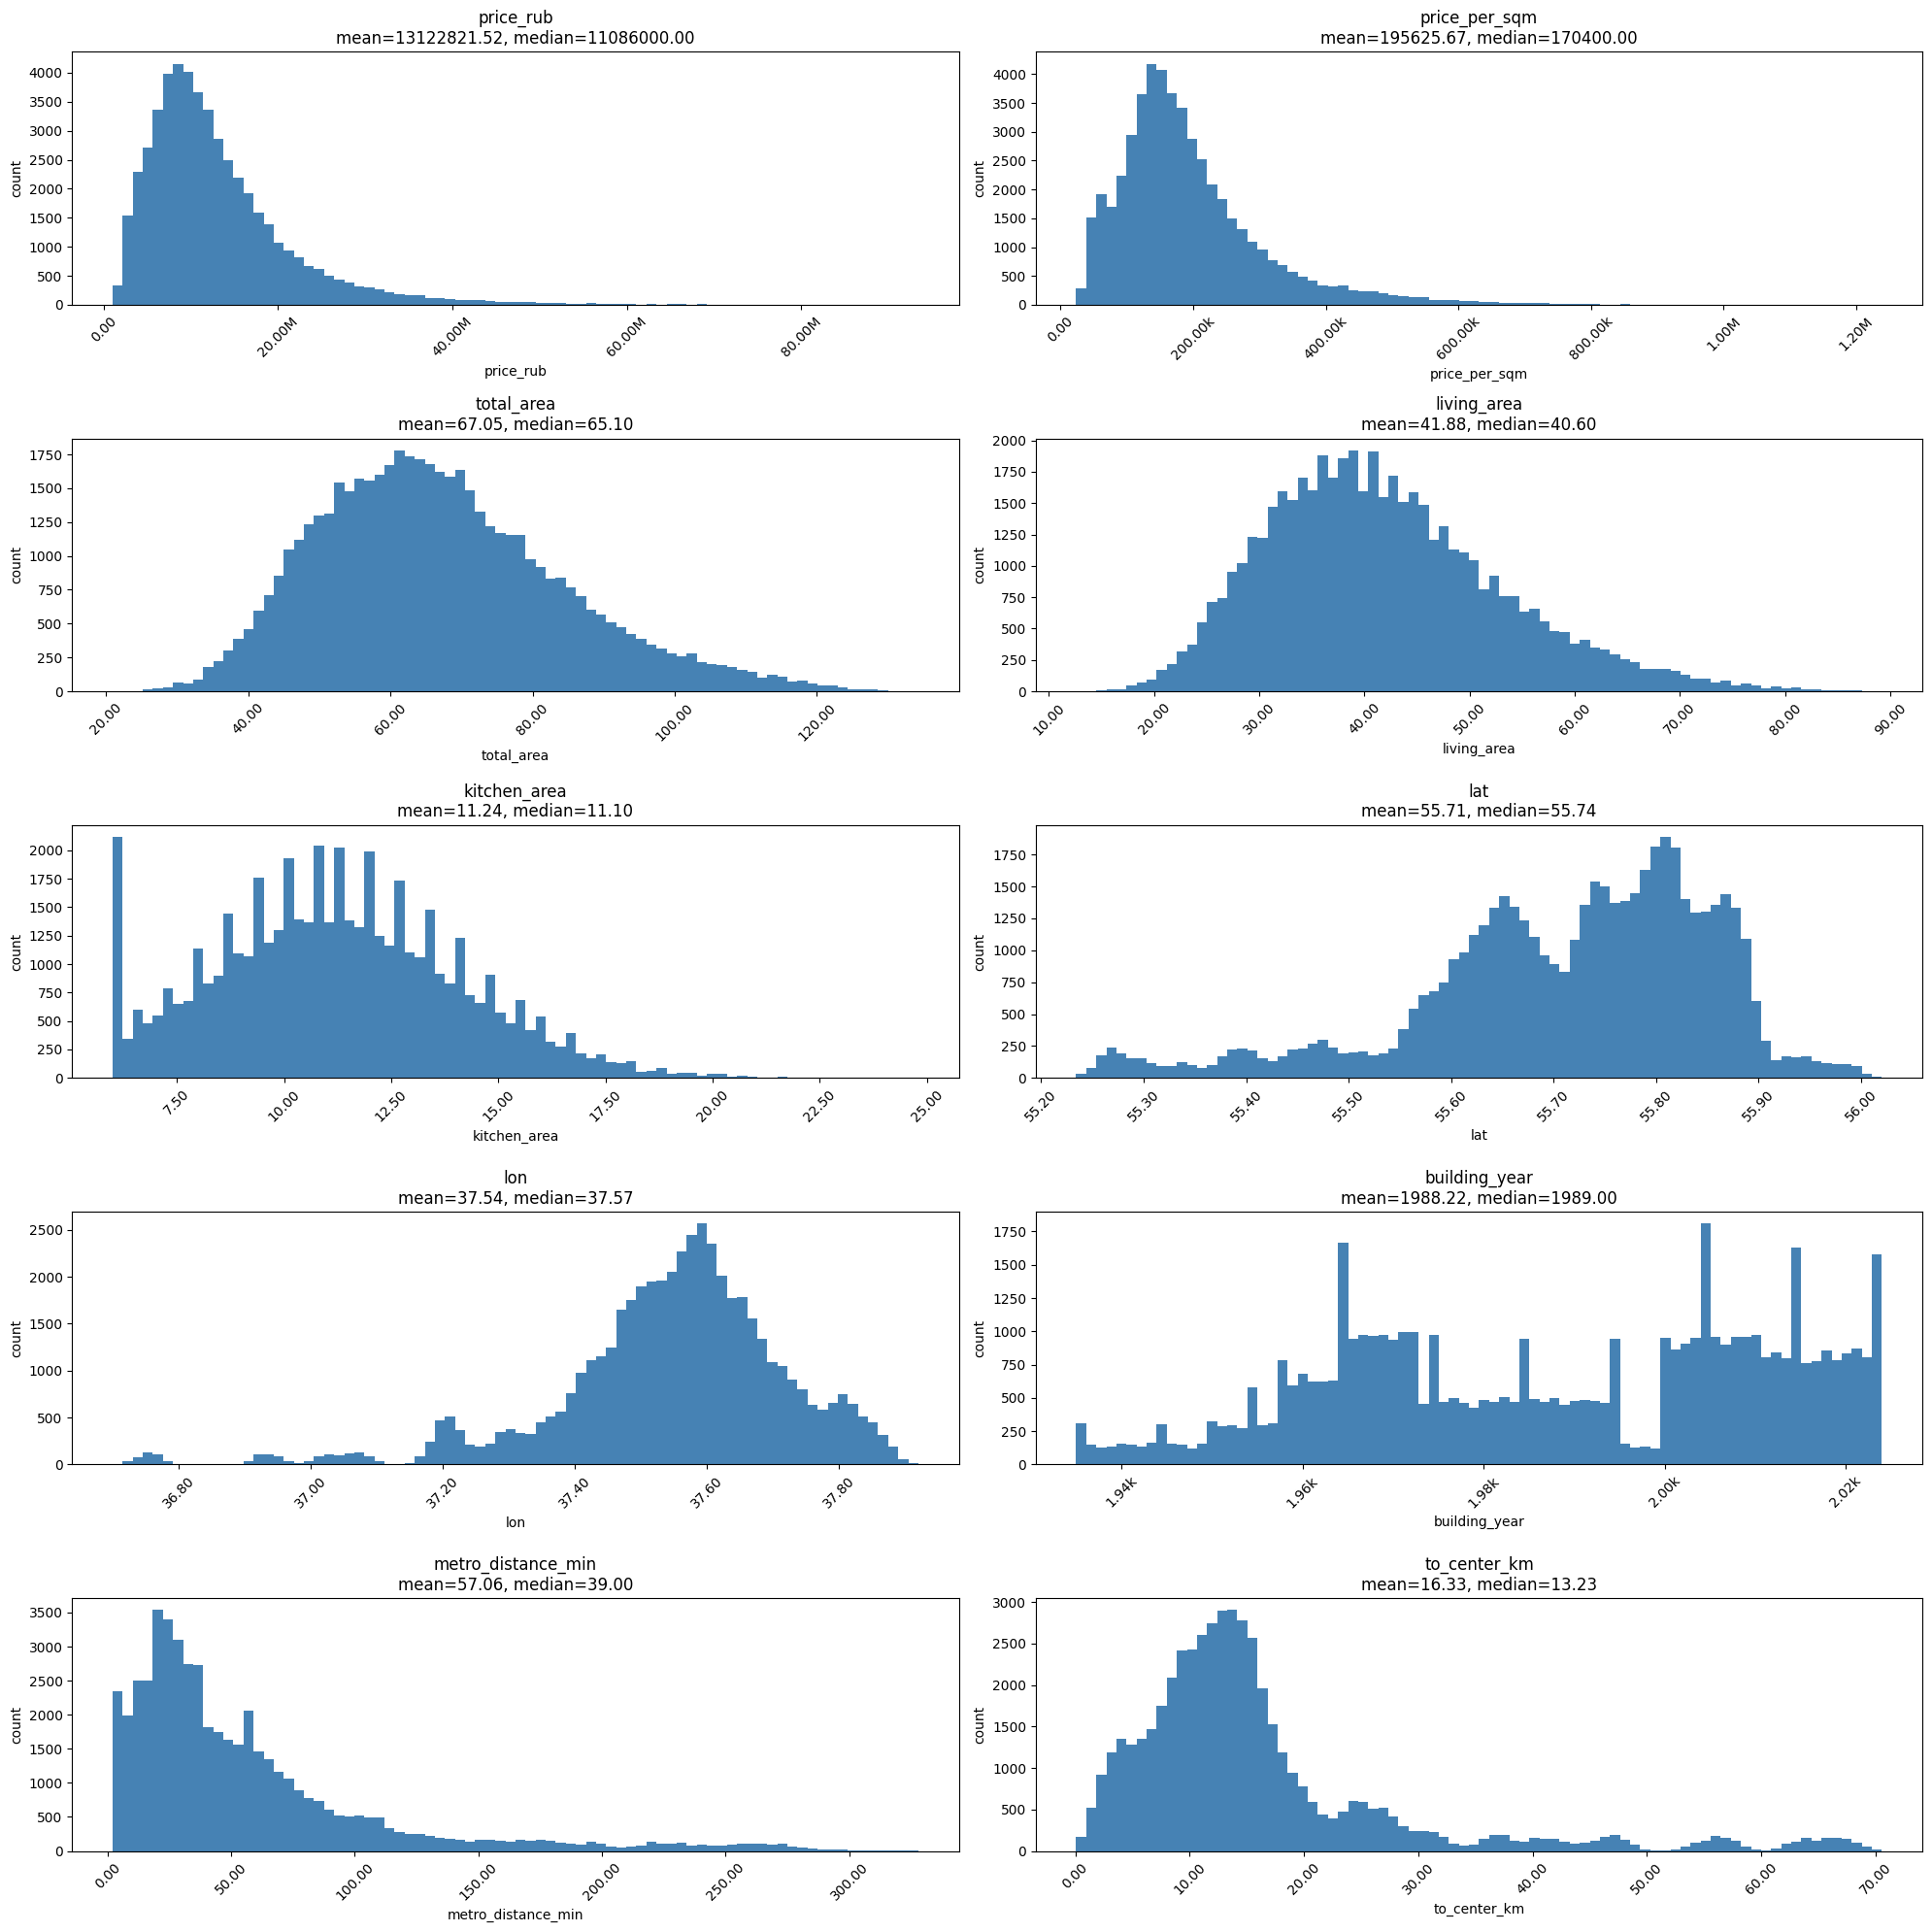

In [16]:
fig, axes = plt.subplots(5, 2, figsize=(20, 20))
axes = axes.ravel()

for i, col in enumerate(numeric_cols):
    axes[i].hist(df_sec_m[col].dropna(), bins=80, color="steelblue", edgecolor="none")
    axes[i].set_title(f"{col}\nmean={df_sec_m[col].mean():.2f}, median={df_sec_m[col].median():.2f}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("count")

    # Убираем 1e+6 и делаем красивые числа
    axes[i].ticklabel_format(style='plain', axis='x')
    axes[i].xaxis.set_major_formatter(mticker.FuncFormatter(fmt))
    axes[i].tick_params(axis='x', rotation=45)


# Убираем пустые оси
for j in range(len(numeric_cols), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

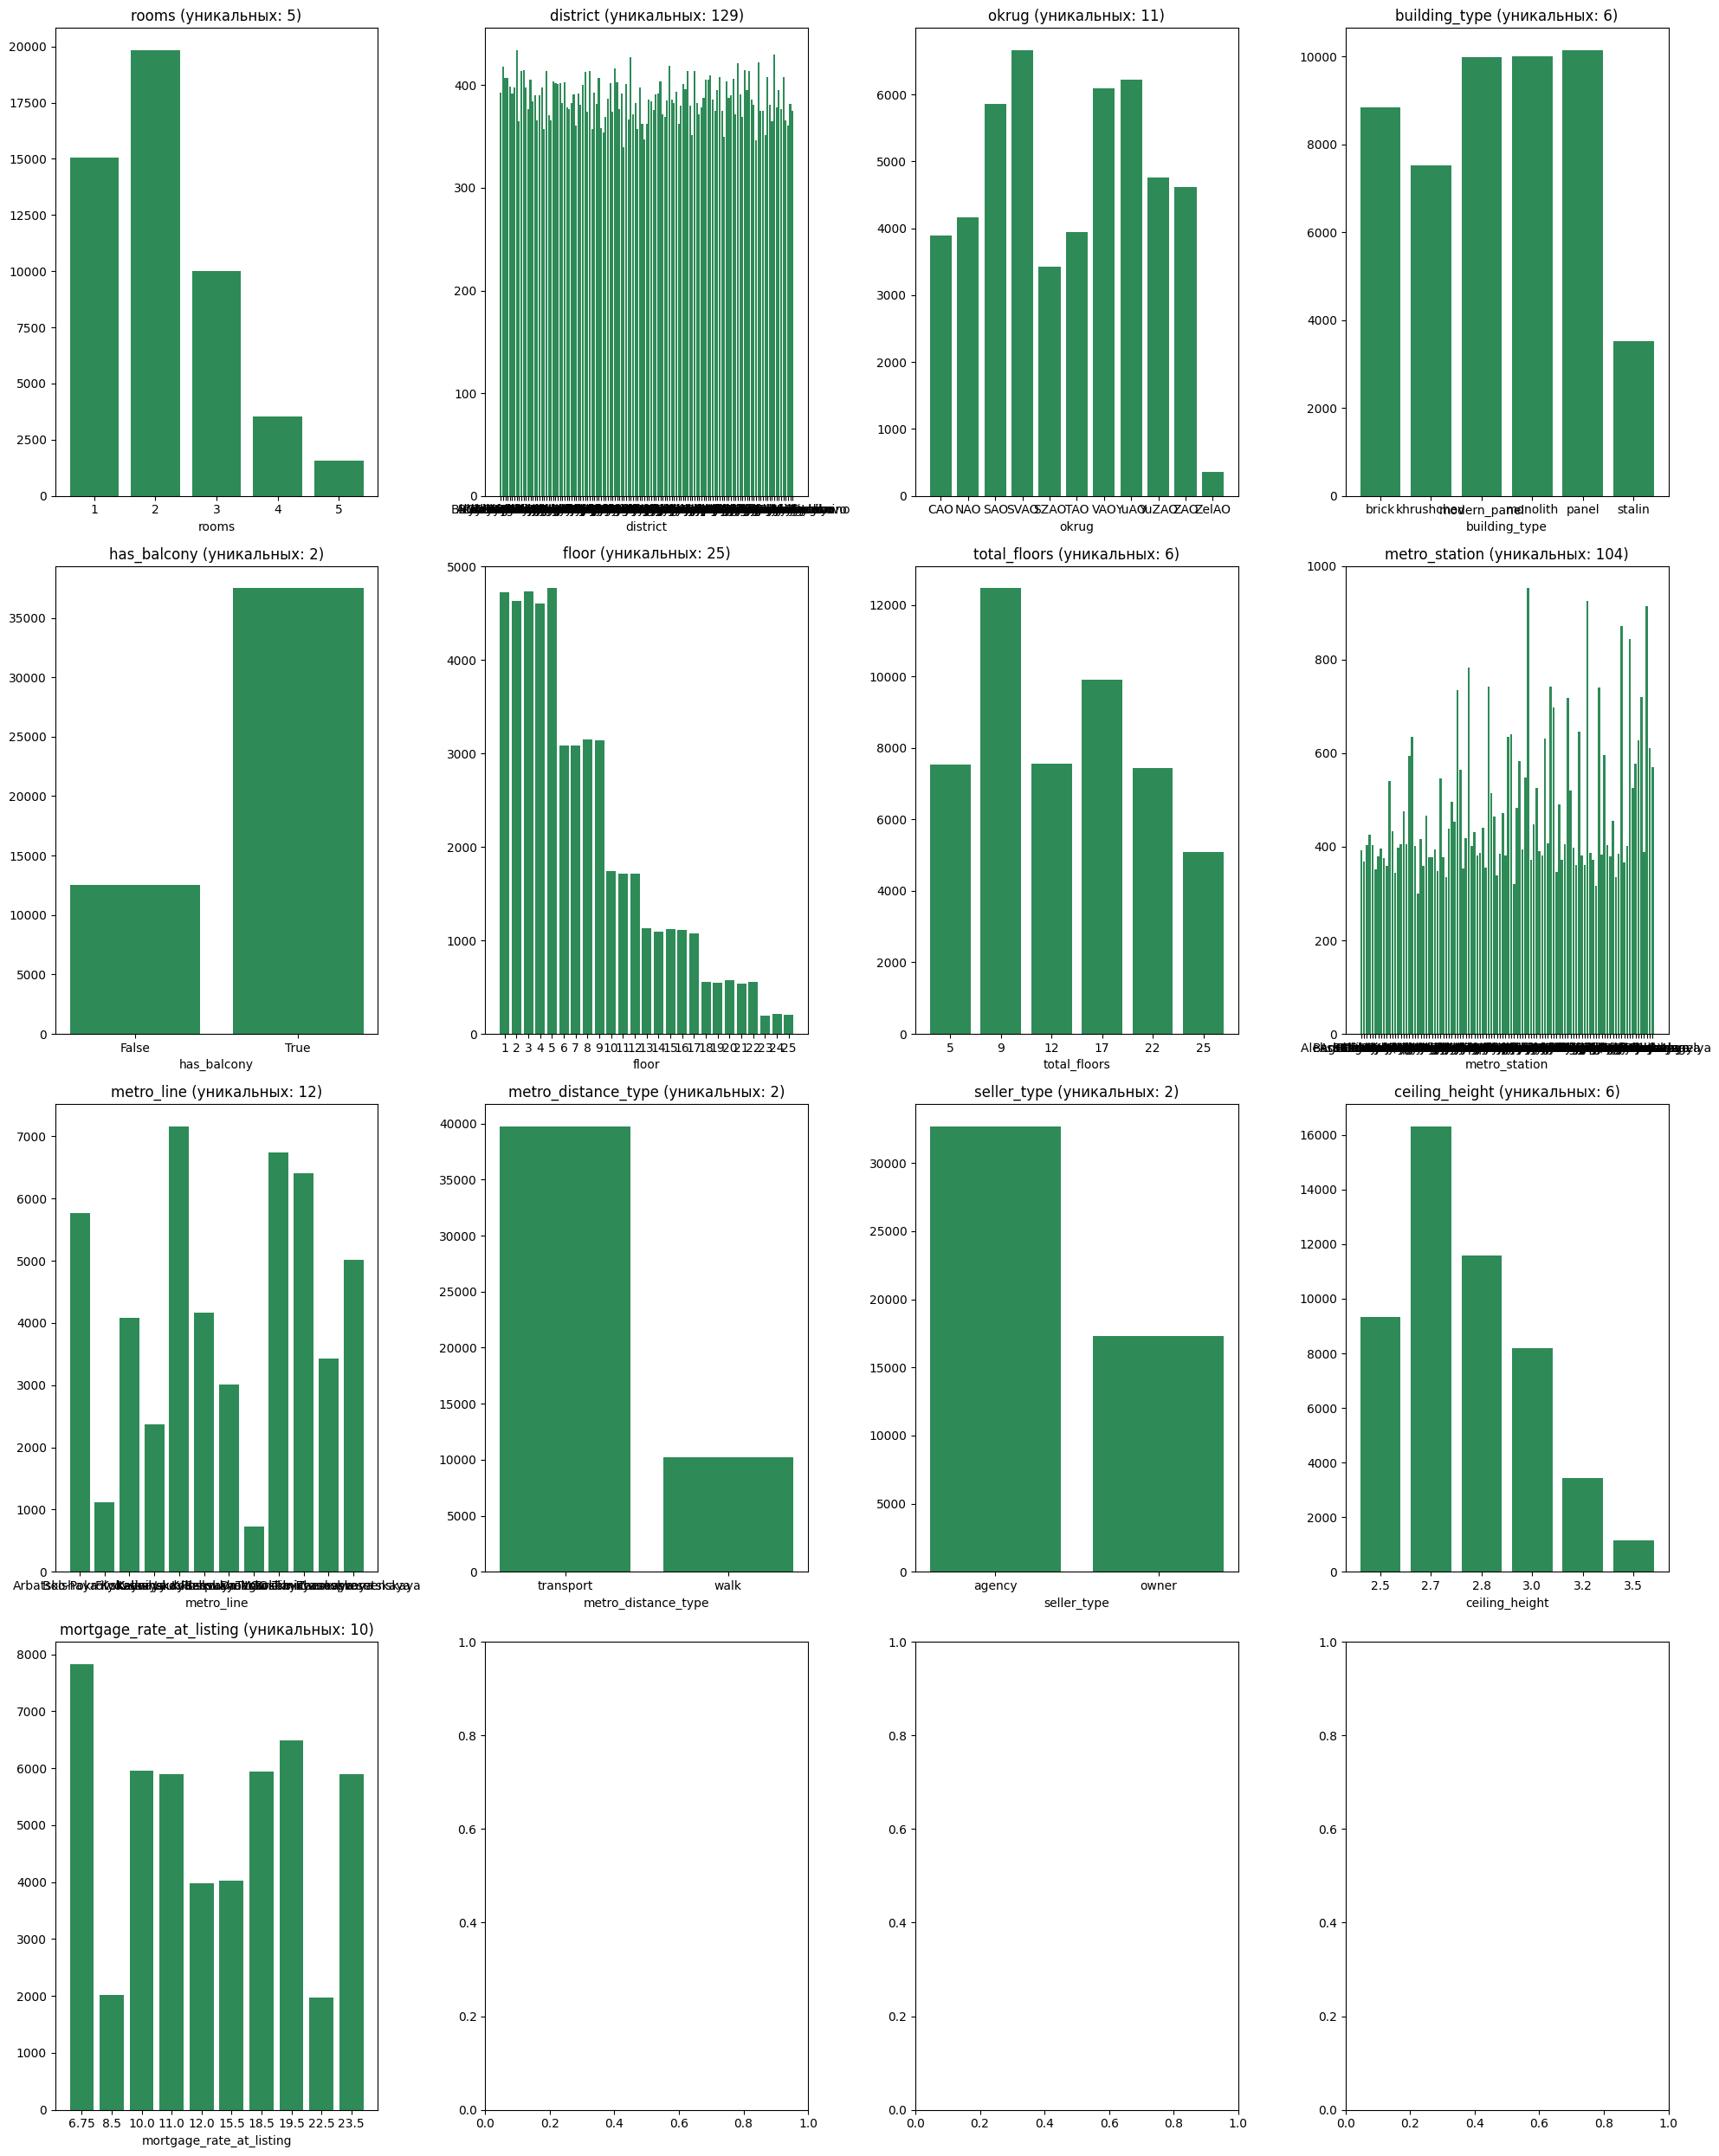

In [17]:
fig, axes = plt.subplots(4, 4, figsize=(20, 25))

for ax, col in zip(axes.ravel(), cat_cols):
    vc = df_sec_m[col].value_counts().sort_index()
    ax.bar(vc.index.astype(str), vc.values, color="seagreen")
    ax.set_title(f"{col} (уникальных: {df_sec_m[col].nunique()})")
    ax.set_xlabel(col)
    ax.tick_params(axis="x", rotation=90 if col == "id_region" else 0)
    if col == "id_region":
        ax.set_xticks(ax.get_xticks()[::5])   # прореживаем подписи

plt.tight_layout()
plt.show()

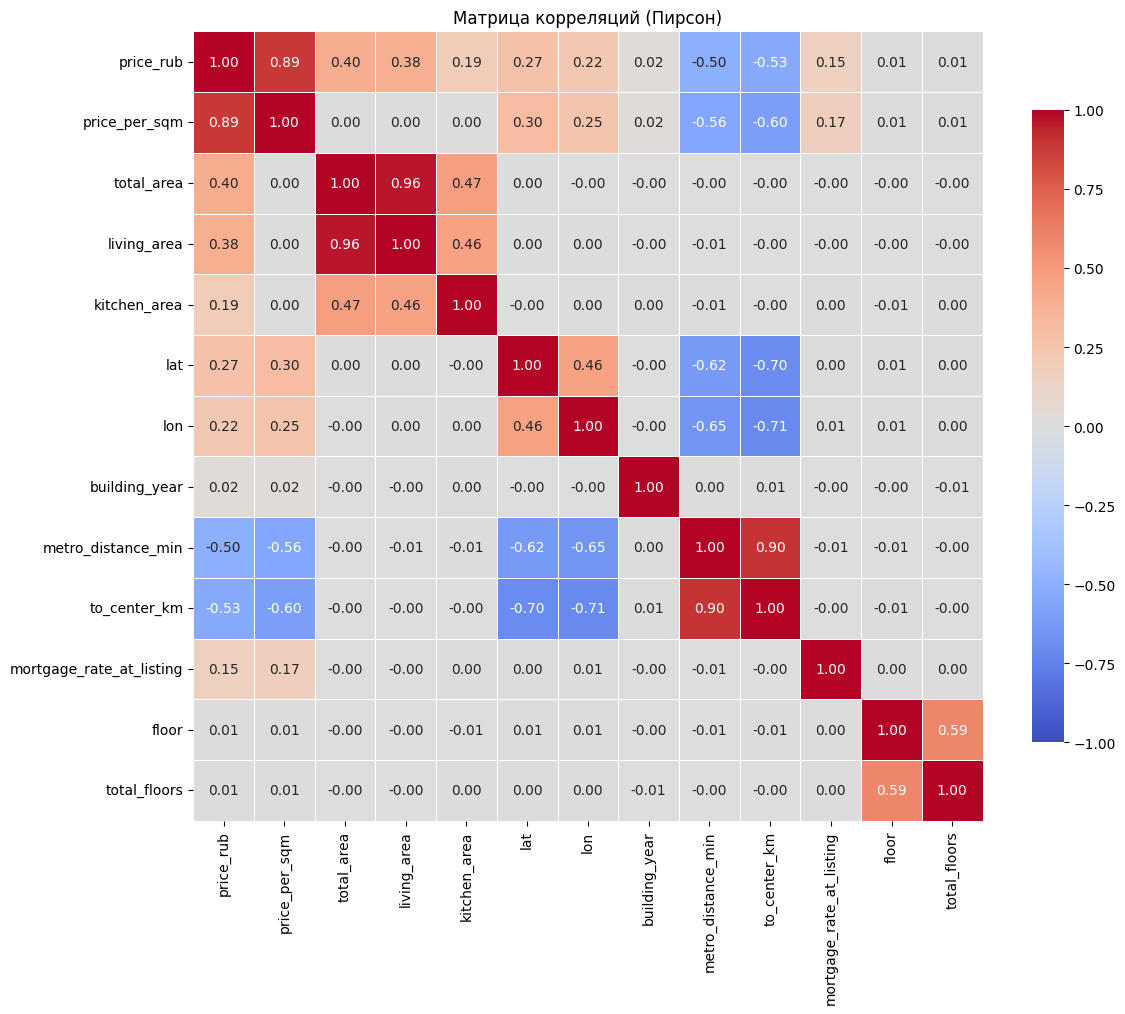

In [18]:
import seaborn as sns
# Только числовые признаки + price
corr_cols = ["price_rub", "price_per_sqm", "total_area", "living_area", "kitchen_area",
                "lat", "lon", "building_year", "metro_distance_min", "to_center_km", "mortgage_rate_at_listing", "floor", 
            "total_floors"]

corr = df_sec_m[corr_cols].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1, vmax=1,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8}
)
plt.title("Матрица корреляций (Пирсон)")
plt.tight_layout()
plt.show()

---
[Все части](README.md) · [Часть 2. Подготовка признаков и нормализация](02_features.ipynb) →

---


# 2. Подготовка признаков и нормализация

**Проект:** прогноз цены квартиры на вторичном рынке Москвы по датасету `Moscow_Real_Estate`.

**В этой части:**
- удаление `price_per_sqm` и `id`, признаки из даты публикации: тренд, месяц, день недели;
- возраст дома вместо года постройки, доля жилой площади, кодирование категорий;
- корреляции Спирмена после кодирования и поиск сильно связанных пар признаков;
- разбиение на train / val / test, `QuantileTransformer` для числовых признаков, `log1p` для цены.

**Графики для отчёта:**
- рисунок 4 — медианная цена квартиры по месяцам публикации: [`figures/fig_04_median_price_by_month.png`](figures/fig_04_median_price_by_month.png)
- рисунок 5 — корреляции Спирмена после кодирования признаков: [`figures/fig_05_spearman_correlation.png`](figures/fig_05_spearman_correlation.png)

> Код продолжает предыдущие части и использует их переменные. Результаты уже сохранены в блокноте, поэтому его можно читать без запуска. Чтобы пересчитать часть, сначала выполните в этом же ядре часть 1: `%run -i 01_eda.ipynb`.

← [Часть 1. Загрузка данных и разведочный анализ](01_eda.ipynb) · [Все части](README.md) · [Часть 3. Первое сравнение моделей: CatBoost, LightGBM, XGBoost](03_boosting_baselines.ipynb) →

## Работа с фичами

In [19]:
# Убрать цену за квадрат
df_sec_m = df_sec_m.drop(columns=['price_per_sqm', 'id'])

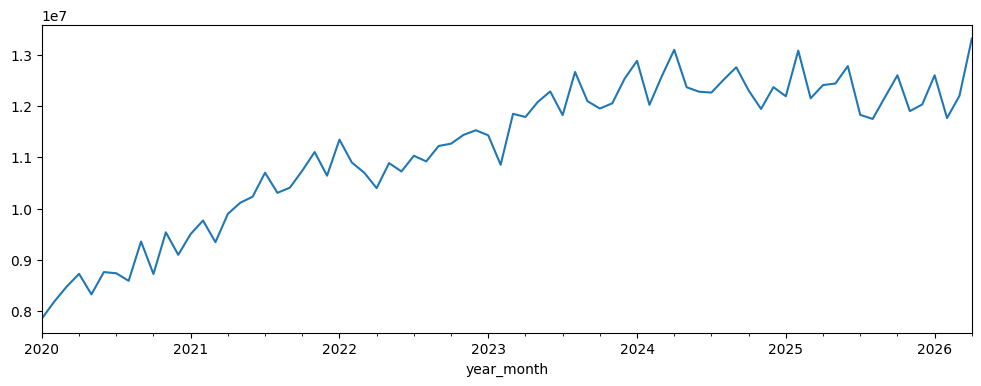

           date_ord  price_rub
date_ord   1.000000   0.190374
price_rub  0.190374   1.000000


In [20]:
df_sec_m['date_posted'] = pd.to_datetime(df_sec_m['date_posted'])
df_sec_m['year_month'] = df_sec_m['date_posted'].dt.to_period('M')

# Средняя цена по месяцам
df_sec_m.groupby('year_month')['price_rub'].median().plot(figsize=(12, 4))
plt.show()

# Корреляция даты и цены (Спирмен)
df_sec_m['date_ord'] = df_sec_m['date_posted'].map(pd.Timestamp.toordinal)
print(df_sec_m[['date_ord', 'price_rub']].corr(method='spearman'))

In [21]:
# ДАТА

# 1. Приводим к datetime
df_sec_m['date_posted'] = pd.to_datetime(df_sec_m['date_posted'], errors='coerce')

# 2. Линейный тренд рынка: месяцы от начала данных
date_min = df_sec_m['date_posted'].min()
df_sec_m['months_since_start'] = (
    (df_sec_m['date_posted'].dt.year  - date_min.year) * 12
    + (df_sec_m['date_posted'].dt.month - date_min.month)
).astype('float32')

# 3. Циклические признаки: месяц (сезонность)
df_sec_m['month_sin'] = np.sin(2 * np.pi * df_sec_m['date_posted'].dt.month / 12).astype('float32')
df_sec_m['month_cos'] = np.cos(2 * np.pi * df_sec_m['date_posted'].dt.month / 12).astype('float32')

# 4. Циклические признаки: день недели (активность рынка)
df_sec_m['dow_sin'] = np.sin(2 * np.pi * df_sec_m['date_posted'].dt.dayofweek / 7).astype('float32')
df_sec_m['dow_cos'] = np.cos(2 * np.pi * df_sec_m['date_posted'].dt.dayofweek / 7).astype('float32')

# 5. Дополнительно: квартал (грубая сезонность)
df_sec_m['quarter_sin'] = np.sin(2 * np.pi * df_sec_m['date_posted'].dt.quarter / 4).astype('float32')
df_sec_m['quarter_cos'] = np.cos(2 * np.pi * df_sec_m['date_posted'].dt.quarter / 4).astype('float32')

# 6. Удаляем исходную дату — она больше не нужна
df_sec_m = df_sec_m.drop(columns=['date_posted'])

# Проверка
print("Новые признаки:")
print(df_sec_m[['months_since_start', 'month_sin', 'month_cos',
                'dow_sin', 'dow_cos', 'quarter_sin', 'quarter_cos']].describe())

Новые признаки:
       months_since_start     month_sin     month_cos       dow_sin  \
count        50000.000000  5.000000e+04  5.000000e+04  50000.000000   
mean            37.458858  3.738302e-02  1.214971e-02     -0.002712   
std             21.868561  7.119077e-01  7.011863e-01      0.707106   
min              0.000000 -1.000000e+00 -1.000000e+00     -0.974928   
25%             19.000000 -5.000000e-01 -5.000000e-01     -0.781832   
50%             38.000000  1.224647e-16  6.123234e-17      0.000000   
75%             56.000000  8.660254e-01  8.660254e-01      0.781832   
max             75.000000  1.000000e+00  1.000000e+00      0.974928   

            dow_cos   quarter_sin   quarter_cos  
count  50000.000000  5.000000e+04  5.000000e+04  
mean       0.000843  3.820000e-02 -8.120000e-03  
std        0.707116  7.150042e-01  6.980428e-01  
min       -0.900969 -1.000000e+00 -1.000000e+00  
25%       -0.900969 -2.449294e-16 -1.836970e-16  
50%       -0.222521  1.224647e-16  6.123234e

In [22]:
# Возраст вместо года
df_sec_m['building_age'] = 2026 - df_sec_m['building_year']
df_sec_m = df_sec_m.drop(columns=['building_year'])

In [23]:
df_sec_m = df_sec_m.drop(columns=['total_floors'])

In [24]:
df_sec_m['living_share'] = df_sec_m['living_area'] / df_sec_m['total_area'].clip(lower=1)

In [25]:
# Кодирование
# Явно приводим булев к float32
cat_cols = df_sec_m.select_dtypes(include=['object', 'category']).columns.tolist()

# 2.1. Разделяем по числу уникальных значений
nunique = df_sec_m[cat_cols].nunique(dropna=True)

binary_cat_cols = [c for c in cat_cols if nunique[c] == 2]
binary_cat_cols.append("has_balcony")
multi_cat_cols  = [c for c in cat_cols if nunique[c] > 2]

print(f"Бинарных категориальных: {len(binary_cat_cols)}")
print(f"Многозначных категориальных: {len(multi_cat_cols)}")

# 2.2. Бинарные → 0/1 (float32, пойдут в bin_cols)
for c in binary_cat_cols:
    vals = df_sec_m[c].dropna().unique()
    df_sec_m[c] = df_sec_m[c].map({vals[0]: 0, vals[1]: 1}).astype('float32')

# 2.3. Многозначные → целочисленные коды (для эмбеддингов)
# ВАЖНО: кодируем по всему df, чтобы коды совпадали в train/val
cat_cardinalities = {}
for c in multi_cat_cols:
    df_sec_m[c] = df_sec_m[c].astype('category')
    cat_cardinalities[c] = len(df_sec_m[c].cat.categories)
    df_sec_m[c] = df_sec_m[c].cat.codes.astype('int64')

print("Кардинальности:", cat_cardinalities)

Бинарных категориальных: 3
Многозначных категориальных: 6
Кардинальности: {'district': 129, 'okrug': 11, 'building_type': 6, 'renovation': 4, 'metro_station': 104, 'metro_line': 12}


In [26]:
df_sec_m.describe()

,district,okrug,lat,lon,total_area,living_area,kitchen_area,rooms,floor,building_type,...,date_ord,months_since_start,month_sin,month_cos,dow_sin,dow_cos,quarter_sin,quarter_cos,building_age,living_share
count,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,...,50000.000000,50000.000000,5.000000e+04,5.000000e+04,50000.000000,50000.000000,5.000000e+04,5.000000e+04,50000.00000,50000.000000
mean,63.774640,4.651960,55.712683,37.543657,67.053158,41.883782,11.244650,2.134900,7.475420,2.312560,...,738579.614840,37.458858,3.738302e-02,1.214971e-02,-0.002712,0.000843,3.820000e-02,-8.120000e-03,37.77992,0.624711
std,37.359904,2.819764,0.143998,0.180338,17.309579,11.209233,2.855538,1.023153,5.530469,1.550443,...,665.601676,21.868561,7.119077e-01,7.011863e-01,0.707106,0.707116,7.150042e-01,6.980428e-01,23.57096,0.043293
min,0.000000,0.000000,55.234080,36.699230,20.900000,12.600000,6.000000,1.000000,1.000000,0.000000,...,737425.000000,0.000000,-1.000000e+00,-1.000000e+00,-0.974928,-0.900969,-1.000000e+00,-1.000000e+00,2.00000,0.548926
25%,31.000000,2.000000,55.635415,37.467110,54.400000,33.700000,9.200000,1.000000,3.000000,1.000000,...,738005.000000,19.000000,-5.000000e-01,-5.000000e-01,-0.781832,-0.900969,-2.449294e-16,-1.836970e-16,17.00000,0.586986
50%,64.000000,5.000000,55.740110,37.565840,65.100000,40.600000,11.100000,2.000000,6.000000,2.000000,...,738582.000000,38.000000,1.224647e-16,6.123234e-17,0.000000,-0.222521,1.224647e-16,6.123234e-17,37.00000,0.624756
75%,96.000000,7.000000,55.817490,37.652020,77.500000,48.500000,13.100000,3.000000,10.000000,4.000000,...,739154.000000,56.000000,8.660254e-01,8.660254e-01,0.781832,0.623490,1.000000e+00,6.123234e-17,58.00000,0.662100
max,128.000000,10.000000,56.020470,37.919860,134.300000,89.200000,24.800000,5.000000,25.000000,5.000000,...,739735.000000,75.000000,1.000000e+00,1.000000e+00,0.974928,1.000000,1.000000e+00,1.000000e+00,91.00000,0.701128


In [27]:
summary = pd.DataFrame({
    'dtype': df_sec_m.dtypes,
    'non_null': df_sec_m.notna().sum(),
    'null': df_sec_m.isna().sum(),
    'null_%': (df_sec_m.isna().mean() * 100).round(2),
    'unique': df_sec_m.nunique(),
    'example': [df_sec_m[c].dropna().iloc[0] if df_sec_m[c].notna().any() else None for c in df_sec_m.columns],
})
summary

,dtype,non_null,null,null_%,unique,example
district,int64,50000,0,0.0,129,7
okrug,int64,50000,0,0.0,11,2
lat,float64,50000,0,0.0,30403,55.79533
lon,float64,50000,0,0.0,33092,37.55519
total_area,float64,50000,0,0.0,1029,71.0
living_area,float64,50000,0,0.0,702,46.5
kitchen_area,float64,50000,0,0.0,170,6.1
rooms,int64,50000,0,0.0,5,2
floor,int64,50000,0,0.0,25,19
building_type,int64,50000,0,0.0,6,1


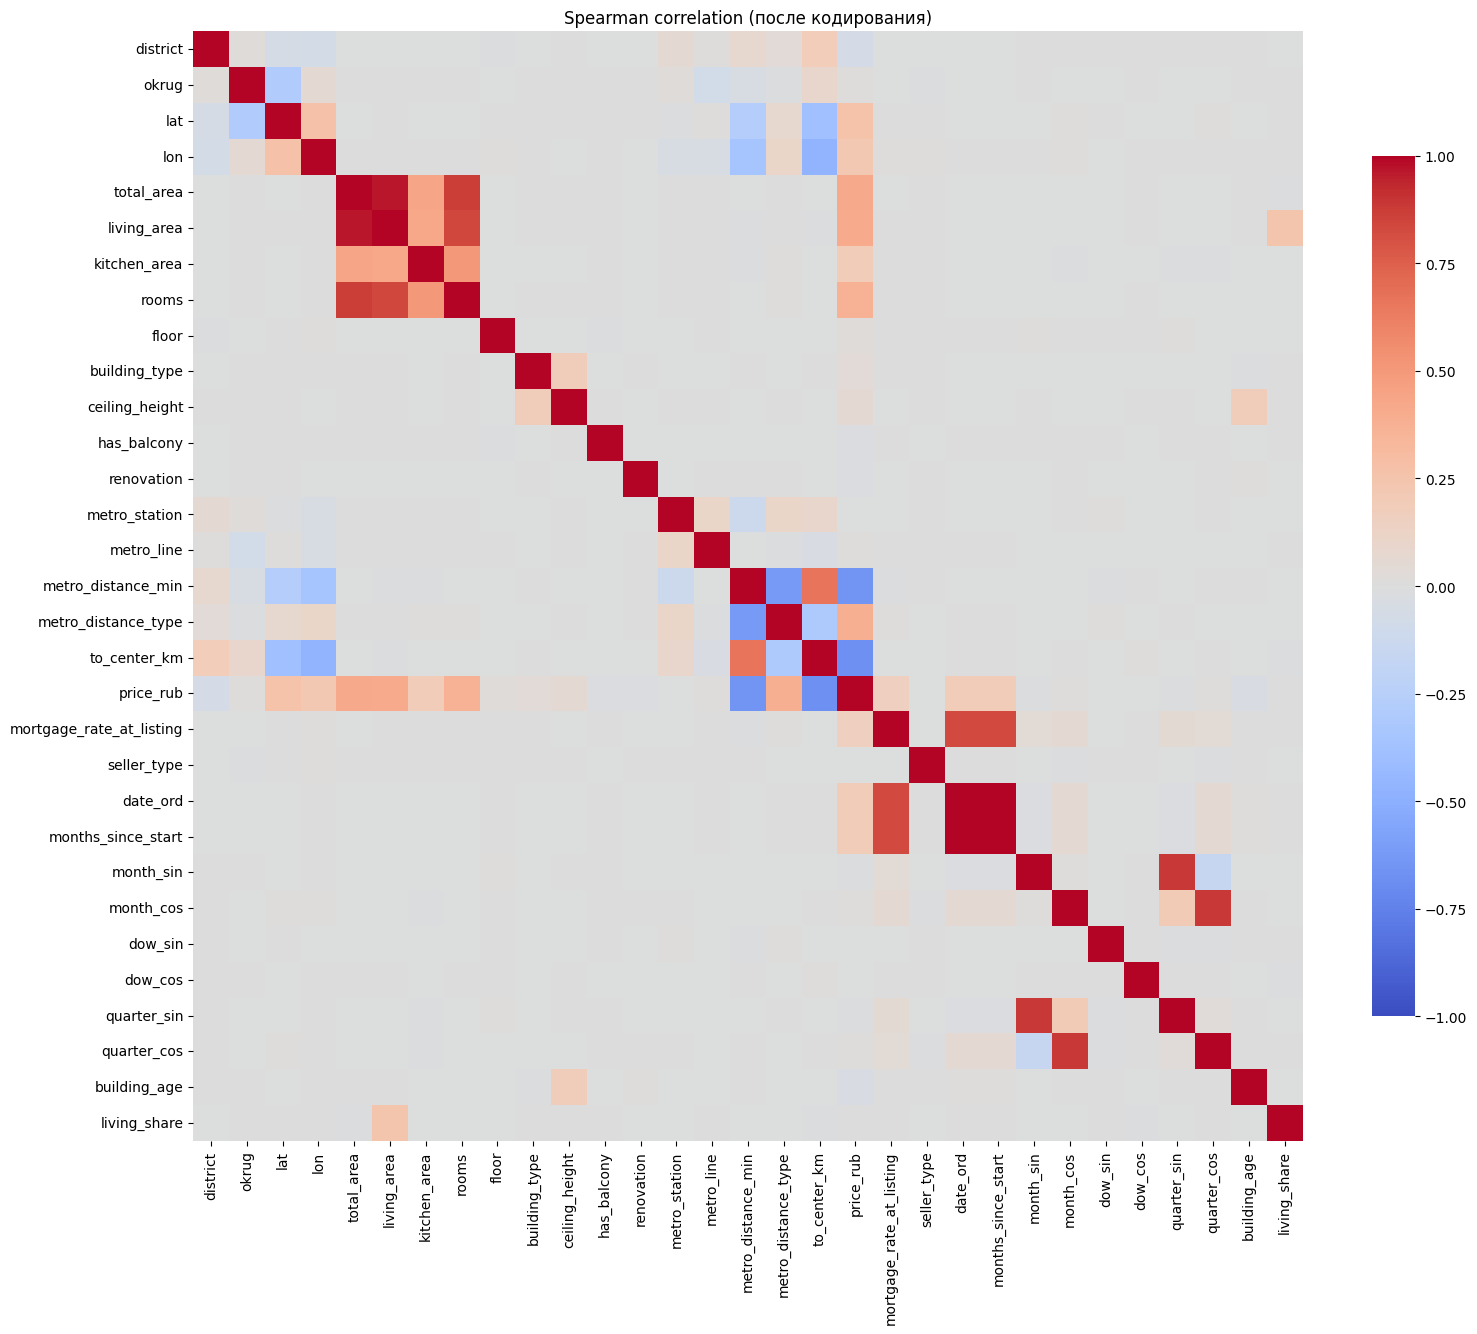

In [28]:
corr = df_sec_m.corr(method='spearman', numeric_only=True)

plt.figure(figsize=(16, 14))
sns.heatmap(
    corr, cmap='coolwarm', center=0,
    vmin=-1, vmax=1, square=True,
    cbar_kws={'shrink': 0.7}
)
plt.title('Spearman correlation (после кодирования)')
plt.tight_layout()
plt.show()

In [29]:
target_corr = (
    df_sec_m.corr(method='spearman', numeric_only=True)['price_rub']
    .drop('price_rub')
    .sort_values(key=abs, ascending=False)
)

print(target_corr.head(30))

to_center_km               -0.678292
metro_distance_min         -0.652246
total_area                  0.420567
living_area                 0.409018
metro_distance_type         0.387308
rooms                       0.367675
lat                         0.263167
lon                         0.224219
kitchen_area                0.192598
months_since_start          0.190421
date_ord                    0.190374
mortgage_rate_at_listing    0.164043
district                   -0.065484
ceiling_height              0.055678
building_type               0.038378
building_age               -0.032497
renovation                 -0.022489
has_balcony                -0.018111
floor                       0.016536
month_sin                  -0.014896
okrug                       0.013893
quarter_sin                -0.013652
metro_line                  0.012619
month_cos                   0.008507
quarter_cos                 0.008026
metro_station              -0.005742
living_share                0.005585
d

In [30]:
threshold = 0.85

corr_abs = corr.abs()
upper = corr_abs.where(np.triu(np.ones(corr_abs.shape), k=1).astype(bool))

pairs = (
    upper.stack()
    .reset_index()
    .rename(columns={'level_0': 'col1', 'level_1': 'col2', 0: 'corr'})
    .sort_values('corr', ascending=False)
)
pairs = pairs[pairs['corr'] >= threshold]

print(pairs.head(40))

           col1                col2      corr
420    date_ord  months_since_start  0.999913
114  total_area         living_area  0.962369
447   month_cos         quarter_cos  0.888271
440   month_sin         quarter_sin  0.887428
116  total_area               rooms  0.869926


In [31]:
df_sec_m = df_sec_m.drop(columns=['date_ord'], errors='ignore')
df_sec_m = df_sec_m.drop(columns=['quarter_sin', 'quarter_cos', 'year_month'])

In [32]:
summary = pd.DataFrame({
    'dtype': df_sec_m.dtypes,
    'non_null': df_sec_m.notna().sum(),
    'null': df_sec_m.isna().sum(),
    'null_%': (df_sec_m.isna().mean() * 100).round(2),
    'unique': df_sec_m.nunique(),
    'example': [df_sec_m[c].dropna().iloc[0] if df_sec_m[c].notna().any() else None for c in df_sec_m.columns],
})
summary

,dtype,non_null,null,null_%,unique,example
district,int64,50000,0,0.0,129,7.000000e+00
okrug,int64,50000,0,0.0,11,2.000000e+00
lat,float64,50000,0,0.0,30403,5.579533e+01
lon,float64,50000,0,0.0,33092,3.755519e+01
total_area,float64,50000,0,0.0,1029,7.100000e+01
living_area,float64,50000,0,0.0,702,4.650000e+01
kitchen_area,float64,50000,0,0.0,170,6.100000e+00
rooms,int64,50000,0,0.0,5,2.000000e+00
floor,int64,50000,0,0.0,25,1.900000e+01
building_type,int64,50000,0,0.0,6,1.000000e+00


## Нормализация

In [33]:
from sklearn.preprocessing import QuantileTransformer
from sklearn.model_selection import train_test_split

In [34]:
TARGET = 'price_rub'

# Категориальные (для эмбеддингов)
cat_cols = ['district', 'okrug', 'metro_station', 'metro_line',
            'building_type', 'renovation']

# Циклические — не нормализуем
cyclic_cols = ['month_sin', 'month_cos', 'dow_sin', 'dow_cos']

# Бинарные — не нормализуем
bin_cols = ['has_balcony', 'metro_distance_type', 'seller_type']

# Числовые — нормализуем
excluded = set(cat_cols + cyclic_cols + bin_cols + [TARGET])
num_cols = [c for c in df_sec_m.columns if c not in excluded]
print("Числовые:", num_cols)

Числовые: ['lat', 'lon', 'total_area', 'living_area', 'kitchen_area', 'rooms', 'floor', 'ceiling_height', 'metro_distance_min', 'to_center_km', 'mortgage_rate_at_listing', 'months_since_start', 'building_age', 'living_share']


In [35]:
from sklearn.model_selection import train_test_split
idx_train_val, idx_test = train_test_split(
    df_sec_m.index, test_size=0.15, random_state=42
)
idx_tr, idx_val = train_test_split(
    idx_train_val, test_size=0.176, random_state=42  # 15/85
)
print(f"Train: {len(idx_tr)}, Val: {len(idx_val)}")

Train: 35020, Val: 7480


In [36]:
qt = QuantileTransformer(
    output_distribution='normal',
    n_quantiles=min(1000, len(idx_tr)),
    random_state=42
)
# числовые
X_num_tr  = qt.fit_transform(
    df_sec_m.loc[idx_tr, num_cols]
).astype('float32')

X_num_val = qt.transform(
    df_sec_m.loc[idx_val, num_cols]
).astype('float32')

X_num_test = qt.transform(df_sec_m.loc[idx_test, num_cols]).astype('float32')

print("X_num_tr:", X_num_tr.shape, "| X_num_val:", X_num_val.shape)

X_num_tr: (35020, 14) | X_num_val: (7480, 14)


In [37]:
# бинарные
X_bin_tr  = df_sec_m.loc[idx_tr,  bin_cols].astype('float32').values
X_bin_val = df_sec_m.loc[idx_val, bin_cols].astype('float32').values
X_bin_test = df_sec_m.loc[idx_test, bin_cols].astype('float32').values
# циклические
X_cyc_tr  = df_sec_m.loc[idx_tr,  cyclic_cols].astype('float32').values
X_cyc_val = df_sec_m.loc[idx_val, cyclic_cols].astype('float32').values
X_cyc_test = df_sec_m.loc[idx_test, cyclic_cols].astype('float32').values
print("X_bin_tr:", X_bin_tr.shape, "| X_cyc_tr:", X_cyc_tr.shape)

X_bin_tr: (35020, 3) | X_cyc_tr: (35020, 4)


In [38]:
# Категориальный
X_cat_tr  = df_sec_m.loc[idx_tr,  multi_cat_cols].values.astype('int64')
X_cat_val = df_sec_m.loc[idx_val, multi_cat_cols].values.astype('int64')
X_cat_test = df_sec_m.loc[idx_test, multi_cat_cols].values.astype('int64')

print("X_cat_tr:", X_cat_tr.shape, "| X_cat_val:", X_cat_val.shape)

X_cat_tr: (35020, 6) | X_cat_val: (7480, 6)


In [39]:
# Целевая log1p
y_tr  = np.log1p(df_sec_m.loc[idx_tr,  TARGET].values).astype('float32')
y_val = np.log1p(df_sec_m.loc[idx_val, TARGET].values).astype('float32')
y_test = np.log1p(df_sec_m.loc[idx_test, TARGET].values).astype('float32')
print("y_tr:", y_tr.shape, "| min:", y_tr.min(), "| max:", y_tr.max())

y_tr: (35020,) | min: 13.834333 | max: 18.352798


In [40]:
# Сборка
X_cont_tr  = np.hstack([X_num_tr,  X_bin_tr,  X_cyc_tr])
X_cont_val = np.hstack([X_num_val, X_bin_val, X_cyc_val])
X_cont_test = np.hstack([X_num_test, X_bin_test, X_cyc_test])

n_cont = X_cont_tr.shape[1]
n_cat  = len(multi_cat_cols)

print(f"X_cont: {X_cont_tr.shape} | X_cat: {X_cat_tr.shape}")
print(f"n_cont={n_cont}, n_cat={n_cat}")

X_cont: (35020, 21) | X_cat: (35020, 6)
n_cont=21, n_cat=6


---
← [Часть 1. Загрузка данных и разведочный анализ](01_eda.ipynb) · [Все части](README.md) · [Часть 3. Первое сравнение моделей: CatBoost, LightGBM, XGBoost](03_boosting_baselines.ipynb) →

---


# 3. Первое сравнение моделей: CatBoost, LightGBM, XGBoost

**Проект:** прогноз цены квартиры на вторичном рынке Москвы по датасету `Moscow_Real_Estate`.

**В этой части:**
- обучение CatBoost, LightGBM и XGBoost на логарифме цены;
- метрики MAE, RMSE, MAPE и R² на валидации, сравнение с нейросетью FlatNet;
- взвешенное среднее трёх моделей.

**Главный результат:** CatBoost — MAPE 6,68 %, LightGBM — 7,15 %, XGBoost — 7,97 %, FlatNet — 8,17 %; среднее трёх бустингов — 6,79 %.

> Код продолжает предыдущие части и использует их переменные. Результаты уже сохранены в блокноте, поэтому его можно читать без запуска. Чтобы пересчитать часть, сначала выполните в этом же ядре части 1–2 по порядку: `%run -i 01_eda.ipynb` и так далее.

← [Часть 2. Подготовка признаков и нормализация](02_features.ipynb) · [Все части](README.md) · [Часть 4. Эксперименты с CatBoost](04_catboost_experiments.ipynb) →

## Модель 

In [41]:
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print("Device:", device)

Device: cpu


In [42]:
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "N/A")

PyTorch: 2.14.1+cpu
CUDA available: False
GPU: N/A


In [43]:
corr = df_sec_m.corr(method='spearman', numeric_only=True)['price_rub']
print(corr.sort_values(key=abs, ascending=False).head(30))

price_rub                   1.000000
to_center_km               -0.678292
metro_distance_min         -0.652246
total_area                  0.420567
living_area                 0.409018
metro_distance_type         0.387308
rooms                       0.367675
lat                         0.263167
lon                         0.224219
kitchen_area                0.192598
months_since_start          0.190421
mortgage_rate_at_listing    0.164043
district                   -0.065484
ceiling_height              0.055678
building_type               0.038378
building_age               -0.032497
renovation                 -0.022489
has_balcony                -0.018111
floor                       0.016536
month_sin                  -0.014896
okrug                       0.013893
metro_line                  0.012619
month_cos                   0.008507
metro_station              -0.005742
living_share                0.005585
dow_cos                    -0.005279
seller_type                -0.002995
d

In [44]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

TARGET = 'price_rub'

# Убираем date-подобные
df_ml = df_sec_m.copy()
bad = [c for c in df_ml.columns 
       if pd.api.types.is_period_dtype(df_ml[c])
       or pd.api.types.is_datetime64_any_dtype(df_ml[c])]

if bad:
    print("Удаляем date-подобные:", bad)
    df_ml = df_ml.drop(columns=bad)
else:
    print("Date-подобных нет")
df_ml = df_ml.drop(columns=bad)

# Категориальные — оставляем как есть (строки/категории)
cat_cols = ['district', 'okrug', 'metro_station', 'metro_line',
            'building_type', 'renovation']
cat_cols = [c for c in cat_cols if c in df_ml.columns]

# ВАЖНО: для CatBoost категориальные должны быть строками или int, не category
for c in cat_cols:
    df_ml[c] = df_ml[c].astype(str)

# Циклические оставляем как числа — бустинг сам разберётся
X = df_ml.drop(columns=[TARGET])
y = df_ml[TARGET].values

# Split (тот же random_state, чтобы сравнение было честным)
X_tr, X_val, y_tr, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# log1p для целевой — как в нейросети
y_tr_log  = np.log1p(y_tr)
y_val_log = np.log1p(y_val)

print(f"X_tr: {X_tr.shape}, X_val: {X_val.shape}")
print(f"Категориальных: {len(cat_cols)}")

Date-подобных нет
X_tr: (40000, 27), X_val: (10000, 27)
Категориальных: 6


C:\Users\Computer\AppData\Local\Temp\ipykernel_79900\2697460062.py:10: DeprecationWarning: is_period_dtype is deprecated and will be removed in a future version. Use `isinstance(dtype, pd.PeriodDtype)` instead
  if pd.api.types.is_period_dtype(df_ml[c])


In [45]:
from catboost import CatBoostRegressor
import time

cat_idx = [X.columns.get_loc(c) for c in cat_cols]

model_cb = CatBoostRegressor(
    iterations=5000,
    learning_rate=0.03,
    depth=8,
    l2_leaf_reg=3.0,
    loss_function='RMSE',
    eval_metric='MAPE',
    random_seed=42,
    early_stopping_rounds=200,
    verbose=200,
    cat_features=cat_idx,
)

t0 = time.time()
model_cb.fit(
    X_tr, y_tr_log,
    eval_set=(X_val, y_val_log),
    use_best_model=True,
)
print(f"Обучение: {time.time() - t0:.1f} сек")

0:	learn: 0.0293508	test: 0.0290607	best: 0.0290607 (0)	total: 155ms	remaining: 12m 55s
200:	learn: 0.0050139	test: 0.0049006	best: 0.0049006 (200)	total: 20.7s	remaining: 8m 14s
400:	learn: 0.0044698	test: 0.0044184	best: 0.0044184 (400)	total: 41.1s	remaining: 7m 51s
600:	learn: 0.0042437	test: 0.0042605	best: 0.0042605 (600)	total: 1m 1s	remaining: 7m 29s
800:	learn: 0.0041067	test: 0.0041943	best: 0.0041943 (800)	total: 1m 21s	remaining: 7m 9s
1000:	learn: 0.0040039	test: 0.0041664	best: 0.0041664 (1000)	total: 1m 42s	remaining: 6m 48s
1200:	learn: 0.0039096	test: 0.0041476	best: 0.0041476 (1200)	total: 2m 2s	remaining: 6m 28s
1400:	learn: 0.0038239	test: 0.0041354	best: 0.0041354 (1399)	total: 2m 23s	remaining: 6m 9s
1600:	learn: 0.0037455	test: 0.0041264	best: 0.0041264 (1600)	total: 2m 44s	remaining: 5m 48s
1800:	learn: 0.0036760	test: 0.0041198	best: 0.0041197 (1799)	total: 3m 3s	remaining: 5m 26s
2000:	learn: 0.0036033	test: 0.0041178	best: 0.0041174 (1935)	total: 3m 23s	remai

In [46]:
import lightgbm as lgb

# LightGBM требует категориальные как 'category'
X_tr_lgb = X_tr.copy()
X_val_lgb = X_val.copy()
for c in cat_cols:
    X_tr_lgb[c]  = X_tr_lgb[c].astype('category')
    X_val_lgb[c] = X_val_lgb[c].astype('category')

model_lgb = lgb.LGBMRegressor(
    n_estimators=5000,
    learning_rate=0.03,
    num_leaves=63,
    max_depth=-1,
    min_child_samples=20,
    reg_alpha=0.1,
    reg_lambda=0.1,
    random_state=42,
    n_jobs=-1,
)

model_lgb.fit(
    X_tr_lgb, y_tr_log,
    eval_set=[(X_val_lgb, y_val_log)],
    eval_metric='mape',
    callbacks=[
        lgb.early_stopping(200, verbose=False),
        lgb.log_evaluation(200),
    ],
)

c:\Users\Computer\Desktop\programInj\house-price-predictor-\predictor-service\venv\lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001257 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2467
[LightGBM] [Info] Number of data points in the train set: 40000, number of used features: 27
[LightGBM] [Info] Start training from score 16.203750
[200]	valid_0's mape: 0.00451148	valid_0's l2: 0.00846264
[400]	valid_0's mape: 0.00439244	valid_0's l2: 0.00796881
[600]	valid_0's mape: 0.00440032	valid_0's l2: 0.00798575


,boosting_type,'gbdt'
,num_leaves,63
,max_depth,-1
,learning_rate,0.03
,n_estimators,5000
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,20


In [47]:
import xgboost as xgb

X_tr_xgb = X_tr.copy()
X_val_xgb = X_val.copy()
for c in cat_cols:
    X_tr_xgb[c]  = X_tr_xgb[c].astype('category')
    X_val_xgb[c] = X_val_xgb[c].astype('category')

model_xgb = xgb.XGBRegressor(
    n_estimators=5000,
    learning_rate=0.03,
    max_depth=8,
    reg_alpha=0.1,
    reg_lambda=1.0,
    random_state=42,
    tree_method='hist',
    enable_categorical=True,
    early_stopping_rounds=200,
)

model_xgb.fit(
    X_tr_xgb, y_tr_log,
    eval_set=[(X_val_xgb, y_val_log)],
    verbose=200,
)

[0]	validation_0-rmse:0.59494
[200]	validation_0-rmse:0.10357
[400]	validation_0-rmse:0.10084
[600]	validation_0-rmse:0.10071
[757]	validation_0-rmse:0.10079


,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,200
,enable_categorical,True
,eval_metric,None


In [48]:
def evaluate(name, model, X_val, y_val_true):
    pred_log = model.predict(X_val)
    pred = np.expm1(pred_log)
    true = np.expm1(y_val_true)

    mae  = np.mean(np.abs(pred - true))
    rmse = np.sqrt(np.mean((pred - true) ** 2))
    mape = np.mean(np.abs((pred - true) / true)) * 100
    r2   = 1 - np.sum((true - pred) ** 2) / np.sum((true - true.mean()) ** 2)

    print(f"\n=== {name} ===")
    print(f"MAE:  {mae:>12,.0f} руб")
    print(f"RMSE: {rmse:>12,.0f} руб")
    print(f"MAPE: {mape:>12.2f} %")
    print(f"R²:   {r2:>12.4f}")
    return {'mae': mae, 'rmse': rmse, 'mape': mape, 'r2': r2, 'pred': pred}


res_cb  = evaluate("CatBoost", model_cb,  X_val, y_val_log)
res_lgb = evaluate("LightGBM", model_lgb, X_val_lgb, y_val_log)
res_xgb = evaluate("XGBoost",  model_xgb, X_val_xgb, y_val_log)


=== CatBoost ===
MAE:       888,146 руб
RMSE:    1,349,683 руб
MAPE:         6.68 %
R²:         0.9753

=== LightGBM ===
MAE:       944,329 руб
RMSE:    1,442,982 руб
MAPE:         7.15 %
R²:         0.9717

=== XGBoost ===
MAE:     1,037,238 руб
RMSE:    1,652,607 руб
MAPE:         7.97 %
R²:         0.9629


In [49]:
baseline_nn = {'mape': 8.17, 'r2': 0.9655, 'mae': 1_036_322, 'rmse': 1_615_622}

results = pd.DataFrame({
    'NN (FlatNet)': baseline_nn,
    'CatBoost':     {k: v for k, v in res_cb.items()  if k != 'pred'},
    'LightGBM':     {k: v for k, v in res_lgb.items() if k != 'pred'},
    'XGBoost':      {k: v for k, v in res_xgb.items() if k != 'pred'},
}).T

print(results[['mape', 'r2', 'mae', 'rmse']].round(4))

                mape      r2           mae          rmse
NN (FlatNet)  8.1700  0.9655  1.036322e+06  1.615622e+06
CatBoost      6.6846  0.9753  8.881457e+05  1.349683e+06
LightGBM      7.1509  0.9717  9.443293e+05  1.442982e+06
XGBoost       7.9744  0.9629  1.037238e+06  1.652607e+06


In [50]:
pred_ensemble = (
    0.5 * res_cb['pred'] +
    0.3 * res_lgb['pred'] +
    0.2 * res_xgb['pred']
)

true = np.expm1(y_val_log)
mape_ens = np.mean(np.abs((pred_ensemble - true) / true)) * 100
print(f"Ensemble MAPE: {mape_ens:.2f}%")

Ensemble MAPE: 6.79%


---
← [Часть 2. Подготовка признаков и нормализация](02_features.ipynb) · [Все части](README.md) · [Часть 4. Эксперименты с CatBoost](04_catboost_experiments.ipynb) →

---


# 4. Эксперименты с CatBoost

**Проект:** прогноз цены квартиры на вторичном рынке Москвы по датасету `Moscow_Real_Estate`.

**В этой части:**
- разбиение 70 / 15 / 15 для всех экспериментов;
- функции потерь RMSE, MAE и Huber, глубина 10, one-hot для категорий;
- подбор гиперпараметров Optuna и ансамбль экспериментов.

**Главный результат:** лучший — базовый CatBoost с RMSE: MAPE 6,73 % на валидации; Huber не сошёлся.

> Код продолжает предыдущие части и использует их переменные. Результаты уже сохранены в блокноте, поэтому его можно читать без запуска. Чтобы пересчитать часть, сначала выполните в этом же ядре части 1–3 по порядку: `%run -i 01_eda.ipynb` и так далее.

← [Часть 3. Первое сравнение моделей: CatBoost, LightGBM, XGBoost](03_boosting_baselines.ipynb) · [Все части](README.md) · [Часть 5. Новые признаки и CatBoost на них](05_feature_engineering.ipynb) →

## Модель CatBoost

In [51]:
import numpy as np
import pandas as pd
import time
import matplotlib.pyplot as plt
from catboost import CatBoostRegressor
from sklearn.model_selection import train_test_split

# ============================================================
# ДАННЫЕ ДЛЯ CATBOOST (без нормализации, категориальные — строки)
# ============================================================

TARGET = 'price_rub'
df_cb = df_sec_m.copy()

# date-подобные
bad = [c for c in df_cb.columns
       if isinstance(df_cb[c].dtype, pd.PeriodDtype)
       or pd.api.types.is_datetime64_any_dtype(df_cb[c])]
df_cb = df_cb.drop(columns=bad)

# Категориальные — строки для CatBoost
cat_cols = [c for c in ['district', 'okrug', 'metro_station', 'metro_line',
                        'building_type', 'renovation']
            if c in df_cb.columns]
for c in cat_cols:
    df_cb[c] = df_cb[c].astype(str)

X = df_cb.drop(columns=[TARGET])
y = df_cb[TARGET].values
y_log = np.log1p(y)

# Один и тот же split для всех экспериментов
X_tr, X_tmp, y_tr, y_tmp = train_test_split(
    X, y_log, test_size=0.3, random_state=42
)
X_val, X_test, y_val, y_test = train_test_split(
    X_tmp, y_tmp, test_size=0.5, random_state=42
)

cat_idx = [X.columns.get_loc(c) for c in cat_cols]
print(f"train: {X_tr.shape}, val: {X_val.shape}, test: {X_test.shape}")

train: (35000, 27), val: (7500, 27), test: (7500, 27)


In [52]:
def evaluate_model(model, X_val, y_val_log, name=""):
    pred_log = model.predict(X_val)
    pred = np.expm1(pred_log)
    true = np.expm1(y_val_log)

    mae  = np.mean(np.abs(pred - true))
    rmse = np.sqrt(np.mean((pred - true) ** 2))
    mape = np.mean(np.abs((pred - true) / true)) * 100
    r2   = 1 - np.sum((true - pred) ** 2) / np.sum((true - true.mean()) ** 2)

    if name:
        print(f"\n=== {name} ===")
        print(f"MAE:  {mae:>12,.0f} руб")
        print(f"RMSE: {rmse:>12,.0f} руб")
        print(f"MAPE: {mape:>12.2f} %")
        print(f"R²:   {r2:>12.4f}")

    return {'mae': mae, 'rmse': rmse, 'mape': mape, 'r2': r2, 'pred': pred}

In [53]:
# Эксперемент 1
model_1 = CatBoostRegressor(
    iterations=5000,
    learning_rate=0.03,
    depth=8,
    l2_leaf_reg=3.0,
    loss_function='RMSE',
    eval_metric='MAPE',
    random_seed=42,
    early_stopping_rounds=200,
    verbose=500,
    cat_features=cat_idx,
)

t0 = time.time()
model_1.fit(X_tr, y_tr, eval_set=(X_val, y_val), use_best_model=True)
print(f"Обучение: {time.time() - t0:.1f} сек")

res_1 = evaluate_model(model_1, X_val, y_val, "Эксперимент 1: Baseline")

0:	learn: 0.0293197	test: 0.0290249	best: 0.0290249 (0)	total: 104ms	remaining: 8m 42s
500:	learn: 0.0043415	test: 0.0043195	best: 0.0043195 (500)	total: 54.5s	remaining: 8m 9s
1000:	learn: 0.0039637	test: 0.0041845	best: 0.0041845 (1000)	total: 1m 44s	remaining: 6m 55s
1500:	learn: 0.0037253	test: 0.0041533	best: 0.0041533 (1499)	total: 2m 32s	remaining: 5m 55s
2000:	learn: 0.0035188	test: 0.0041436	best: 0.0041433 (1982)	total: 3m 56s	remaining: 5m 54s
Stopped by overfitting detector  (200 iterations wait)

bestTest = 0.00414005026
bestIteration = 2230

Shrink model to first 2231 iterations.
Обучение: 282.7 сек

=== Эксперимент 1: Baseline ===
MAE:       878,979 руб
RMSE:    1,316,360 руб
MAPE:         6.73 %
R²:         0.9759


In [54]:
# Эксперемент 2
model_2 = CatBoostRegressor(
    iterations=5000,
    learning_rate=0.03,
    depth=8,
    l2_leaf_reg=3.0,
    loss_function='MAE',       # ← изменили
    eval_metric='MAPE',
    random_seed=42,
    early_stopping_rounds=200,
    verbose=500,
    cat_features=cat_idx,
)

t0 = time.time()
model_2.fit(X_tr, y_tr, eval_set=(X_val, y_val), use_best_model=True)
print(f"Обучение: {time.time() - t0:.1f} сек")

res_2 = evaluate_model(model_2, X_val, y_val, "Эксперимент 2: MAE loss")

0:	learn: 0.0293230	test: 0.0290414	best: 0.0290414 (0)	total: 86.7ms	remaining: 7m 13s
500:	learn: 0.0043043	test: 0.0044290	best: 0.0044290 (500)	total: 51.1s	remaining: 7m 38s
1000:	learn: 0.0038445	test: 0.0042870	best: 0.0042868 (995)	total: 1m 39s	remaining: 6m 38s
1500:	learn: 0.0036032	test: 0.0042596	best: 0.0042594 (1499)	total: 2m 28s	remaining: 5m 45s
2000:	learn: 0.0034348	test: 0.0042453	best: 0.0042452 (1982)	total: 3m 16s	remaining: 4m 54s
2500:	learn: 0.0033060	test: 0.0042391	best: 0.0042388 (2432)	total: 4m 3s	remaining: 4m 3s
3000:	learn: 0.0032036	test: 0.0042338	best: 0.0042338 (3000)	total: 4m 50s	remaining: 3m 13s
3500:	learn: 0.0031255	test: 0.0042293	best: 0.0042291 (3490)	total: 5m 39s	remaining: 2m 25s
4000:	learn: 0.0030510	test: 0.0042251	best: 0.0042250 (3996)	total: 6m 28s	remaining: 1m 36s
4500:	learn: 0.0029866	test: 0.0042219	best: 0.0042219 (4500)	total: 7m 16s	remaining: 48.4s
4999:	learn: 0.0029235	test: 0.0042200	best: 0.0042199 (4988)	total: 8m 4

In [55]:
# Эксперемент 3
model_3 = CatBoostRegressor(
    iterations=5000,
    learning_rate=0.03,
    depth=8,
    l2_leaf_reg=3.0,
    loss_function='Huber:delta=0.5',   # ← Huber
    eval_metric='MAPE',
    random_seed=42,
    early_stopping_rounds=200,
    verbose=500,
    cat_features=cat_idx,
)

t0 = time.time()
model_3.fit(X_tr, y_tr, eval_set=(X_val, y_val), use_best_model=True)
print(f"Обучение: {time.time() - t0:.1f} сек")

res_3 = evaluate_model(model_3, X_val, y_val, "Эксперимент 3: Huber loss")

0:	learn: 0.8789285	test: 0.8835220	best: 0.8835220 (0)	total: 46.4ms	remaining: 3m 52s
500:	learn: 0.0306235	test: 0.0303891	best: 0.0303891 (500)	total: 48.2s	remaining: 7m 13s
1000:	learn: 0.0235567	test: 0.0231286	best: 0.0231286 (1000)	total: 1m 35s	remaining: 6m 20s
1500:	learn: 0.0189601	test: 0.0186483	best: 0.0186483 (1499)	total: 2m 20s	remaining: 5m 28s
2000:	learn: 0.0179755	test: 0.0178975	best: 0.0178975 (2000)	total: 3m 6s	remaining: 4m 39s
2500:	learn: 0.0170942	test: 0.0173285	best: 0.0173285 (2500)	total: 3m 52s	remaining: 3m 51s
3000:	learn: 0.0161482	test: 0.0167214	best: 0.0167214 (3000)	total: 4m 38s	remaining: 3m 5s
3500:	learn: 0.0155928	test: 0.0164619	best: 0.0164619 (3500)	total: 5m 24s	remaining: 2m 18s
4000:	learn: 0.0151254	test: 0.0162526	best: 0.0162526 (4000)	total: 6m 10s	remaining: 1m 32s
4500:	learn: 0.0147610	test: 0.0161061	best: 0.0161052 (4486)	total: 6m 56s	remaining: 46.1s
4999:	learn: 0.0144683	test: 0.0160016	best: 0.0160016 (4999)	total: 7m 

In [56]:
# Эксперемент 4
model_4 = CatBoostRegressor(
    iterations=10000,
    learning_rate=0.02,       # ← меньше
    depth=10,                 # ← глубже
    l2_leaf_reg=5.0,          # ← больше регуляризации под глубину
    loss_function='RMSE',
    eval_metric='MAPE',
    random_seed=42,
    early_stopping_rounds=300,
    verbose=500,
    cat_features=cat_idx,
)

t0 = time.time()
model_4.fit(X_tr, y_tr, eval_set=(X_val, y_val), use_best_model=True)
print(f"Обучение: {time.time() - t0:.1f} сек")

res_4 = evaluate_model(model_4, X_val, y_val, "Эксперимент 4: depth=10, lr=0.02")

0:	learn: 0.0295360	test: 0.0292469	best: 0.0292469 (0)	total: 135ms	remaining: 22m 26s
500:	learn: 0.0044275	test: 0.0044679	best: 0.0044679 (500)	total: 1m 14s	remaining: 23m 33s
1000:	learn: 0.0039575	test: 0.0042547	best: 0.0042547 (1000)	total: 5m 21s	remaining: 48m 7s
1500:	learn: 0.0036340	test: 0.0042118	best: 0.0042117 (1497)	total: 6m 40s	remaining: 37m 49s
2000:	learn: 0.0033531	test: 0.0041970	best: 0.0041965 (1944)	total: 7m 59s	remaining: 31m 57s
2500:	learn: 0.0031097	test: 0.0041910	best: 0.0041906 (2456)	total: 9m 18s	remaining: 27m 54s
3000:	learn: 0.0028849	test: 0.0041920	best: 0.0041904 (2734)	total: 10m 37s	remaining: 24m 47s
Stopped by overfitting detector  (300 iterations wait)

bestTest = 0.00419038201
bestIteration = 2734

Shrink model to first 2735 iterations.
Обучение: 644.3 сек

=== Эксперимент 4: depth=10, lr=0.02 ===
MAE:       893,255 руб
RMSE:    1,352,354 руб
MAPE:         6.82 %
R²:         0.9746


In [57]:
# Эксперемент 5
model_5 = CatBoostRegressor(
    iterations=5000,
    learning_rate=0.03,
    depth=8,
    l2_leaf_reg=3.0,
    one_hot_max_size=300,     # ← one-hot для всех категорий ≤300 значений
    loss_function='RMSE',
    eval_metric='MAPE',
    random_seed=42,
    early_stopping_rounds=200,
    verbose=500,
    cat_features=cat_idx,
)

t0 = time.time()
model_5.fit(X_tr, y_tr, eval_set=(X_val, y_val), use_best_model=True)
print(f"Обучение: {time.time() - t0:.1f} сек")

res_5 = evaluate_model(model_5, X_val, y_val, "Эксперимент 5: one_hot_max_size=300")

0:	learn: 0.0293731	test: 0.0290830	best: 0.0290830 (0)	total: 6.92ms	remaining: 34.6s
500:	learn: 0.0044483	test: 0.0045856	best: 0.0045856 (500)	total: 2.91s	remaining: 26.1s
1000:	learn: 0.0040369	test: 0.0042973	best: 0.0042973 (1000)	total: 5.8s	remaining: 23.2s
1500:	learn: 0.0037952	test: 0.0042315	best: 0.0042313 (1499)	total: 8.82s	remaining: 20.6s
2000:	learn: 0.0035888	test: 0.0042067	best: 0.0042067 (1999)	total: 11.8s	remaining: 17.6s
2500:	learn: 0.0034014	test: 0.0041955	best: 0.0041954 (2498)	total: 14.6s	remaining: 14.6s
3000:	learn: 0.0032316	test: 0.0041928	best: 0.0041927 (2998)	total: 17.6s	remaining: 11.7s
Stopped by overfitting detector  (200 iterations wait)

bestTest = 0.004190188792
bestIteration = 3208

Shrink model to first 3209 iterations.
Обучение: 20.7 сек

=== Эксперимент 5: one_hot_max_size=300 ===
MAE:       893,865 руб
RMSE:    1,340,844 руб
MAPE:         6.81 %
R²:         0.9750


In [58]:
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)
# Эксперемент 6 optuna ищут лучшие lr, depth, l2, bagging_temperature, random_strength
def objective(trial):
    params = {
        'iterations': 5000,
        'learning_rate': trial.suggest_float('lr', 0.01, 0.08, log=True),
        'depth': trial.suggest_int('depth', 6, 10),
        'l2_leaf_reg': trial.suggest_float('l2', 1, 15, log=True),
        'bagging_temperature': trial.suggest_float('bag', 0, 1),
        'random_strength': trial.suggest_float('rs', 0.1, 3, log=True),
        'border_count': 128,
        'loss_function': 'RMSE',
        'eval_metric': 'MAPE',
        'random_seed': 42,
        'early_stopping_rounds': 200,
        'verbose': False,
        'cat_features': cat_idx,
        'one_hot_max_size': 300,
    }
    model = CatBoostRegressor(**params)
    model.fit(X_tr, y_tr, eval_set=(X_val, y_val), use_best_model=True)
    pred = np.expm1(model.predict(X_val))
    true = np.expm1(y_val)
    return np.mean(np.abs((pred - true) / true)) * 100

study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=30, show_progress_bar=True)

print(f"\nBest MAPE: {study.best_value:.3f}%")
print("Best params:")
for k, v in study.best_params.items():
    print(f"  {k}: {v}")

  0%|          | 0/30 [00:00<?, ?it/s]


Best MAPE: 6.775%
Best params:
  lr: 0.032141501360825844
  depth: 6
  l2: 9.559413979558682
  bag: 0.01066254134296929
  rs: 0.2238797563015466


In [59]:
# Эксперемент 7 Ансамбль топ 3 модели
# Собираем предсказания на val в log-пространстве
preds_val = {
    'baseline':  model_1.predict(X_val),
    'mae':       model_2.predict(X_val),
    'huber':     model_3.predict(X_val),
    'deep':      model_4.predict(X_val),
    'onehot':    model_5.predict(X_val),
}

# Простое среднее
pred_avg_log = np.mean(list(preds_val.values()), axis=0)
pred_avg = np.expm1(pred_avg_log)
true = np.expm1(y_val)

mape_avg = np.mean(np.abs((pred_avg - true) / true)) * 100
print(f"Простое среднее: MAPE={mape_avg:.3f}%")

# Взвешенное (веса — по 1/MAPE²)
weights = {k: 1 / (evaluate_model(m, X_val, y_val)['mape'] ** 2)
           for k, m in [('baseline', model_1), ('mae', model_2),
                        ('huber', model_3), ('deep', model_4),
                        ('onehot', model_5)]}
total_w = sum(weights.values())
print("\nВеса:")
for k, w in weights.items():
    print(f"  {k}: {w/total_w:.3f}")

pred_w_log = sum(preds_val[k] * weights[k] for k in preds_val) / total_w
pred_w = np.expm1(pred_w_log)
mape_w = np.mean(np.abs((pred_w - true) / true)) * 100
print(f"\nВзвешенное среднее: MAPE={mape_w:.3f}%")

Простое среднее: MAPE=9.768%

Веса:
  baseline: 0.256
  mae: 0.246
  huber: 0.000
  deep: 0.249
  onehot: 0.249

Взвешенное среднее: MAPE=6.715%


In [60]:
results = pd.DataFrame({
    'Baseline':      {k: v for k, v in res_1.items() if k != 'pred'},
    'MAE loss':      {k: v for k, v in res_2.items() if k != 'pred'},
    'Huber loss':    {k: v for k, v in res_3.items() if k != 'pred'},
    'depth=10':      {k: v for k, v in res_4.items() if k != 'pred'},
    'one_hot':       {k: v for k, v in res_5.items() if k != 'pred'},
}).T

print(results[['mape', 'r2', 'mae', 'rmse']].round(4))

                   mape            r2           mae          rmse
Baseline         6.7278  9.759000e-01  8.789794e+05  1.316360e+06
MAE loss         6.8549  9.742000e-01  9.020606e+05  1.363507e+06
Huber loss  104507.5139 -6.922013e+08  2.755942e+09  2.232498e+11
depth=10         6.8152  9.746000e-01  8.932550e+05  1.352354e+06
one_hot          6.8119  9.750000e-01  8.938645e+05  1.340844e+06


---
← [Часть 3. Первое сравнение моделей: CatBoost, LightGBM, XGBoost](03_boosting_baselines.ipynb) · [Все части](README.md) · [Часть 5. Новые признаки и CatBoost на них](05_feature_engineering.ipynb) →

---


# 5. Новые признаки и CatBoost на них

**Проект:** прогноз цены квартиры на вторичном рынке Москвы по датасету `Moscow_Real_Estate`.

**В этой части:**
- расстояния до Кремля, Москва-Сити, Лужников и ВДНХ;
- отношения площадей и взаимодействия признаков, средние по району и станции метро;
- CatBoost на 41 признаке и подбор гиперпараметров Optuna.

**Главный результат:** Optuna — MAPE 6,665 % на валидации; параметры сохранены в `best_catboost_params.json`.

> Код продолжает предыдущие части и использует их переменные. Результаты уже сохранены в блокноте, поэтому его можно читать без запуска. Чтобы пересчитать часть, сначала выполните в этом же ядре части 1–4 по порядку: `%run -i 01_eda.ipynb` и так далее.

← [Часть 4. Эксперименты с CatBoost](04_catboost_experiments.ipynb) · [Все части](README.md) · [Часть 6. Ансамбль CatBoost, LightGBM и XGBoost](06_ensemble.ipynb) →

### Feature engineering

In [61]:
# Расстояние до известных мест
# Координаты известных мест
landmarks = {
    'kremlin':   (37.6173, 55.7558),
    'msk_city':  (37.5370, 55.7495),
    'luzhniki':  (37.5544, 55.7158),
    'vdnkh':     (37.6325, 55.8262),
}


import numpy as np

def haversine(lat1, lon1, lat2, lon2):
    """Работает и со скалярами, и с pandas Series через numpy."""
    R = 6371.0  # км
    
    lat1 = np.radians(np.asarray(lat1, dtype=float))
    lon1 = np.radians(np.asarray(lon1, dtype=float))
    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)
    
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    
    a = np.sin(dlat/2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2)**2
    return 2 * R * np.arctan2(np.sqrt(a), np.sqrt(1 - a))

for name, (lon, lat) in landmarks.items():
    df_cb[f'dist_{name}'] = haversine(df_cb['lat'], df_cb['lon'], lat, lon)

In [62]:
# Отношения и взаимодействия
df_cb['area_per_room']     = df_cb['total_area'] / df_cb['rooms'].clip(lower=1)
df_cb['kitchen_share']     = df_cb['kitchen_area'] / df_cb['total_area'].clip(lower=1)
df_cb['living_share']      = df_cb['living_area'] / df_cb['total_area'].clip(lower=1)
df_cb['ceiling_per_area']  = df_cb['ceiling_height'] / df_cb['total_area'].clip(lower=1)
df_cb['age_per_floor']     = df_cb['building_age'] / df_cb['floor'].clip(lower=1)
df_cb['center_x_area']     = df_cb['to_center_km'] * df_cb['total_area']
df_cb['metro_x_area']      = df_cb['metro_distance_min'] * df_cb['total_area']

In [63]:
# Агрегаты fit только на train; для отсутствующих групп используется среднее train.
from sklearn.model_selection import train_test_split

idx_tr, idx_tmp = train_test_split(df_cb.index, test_size=0.3, random_state=42)
idx_val, idx_test = train_test_split(idx_tmp, test_size=0.5, random_state=42)

AGGREGATE_SPECS = {
    'district_avg_area': ('district', 'total_area'),
    'district_avg_age': ('district', 'building_age'),
    'district_avg_ceiling': ('district', 'ceiling_height'),
    'station_avg_area': ('metro_station', 'total_area'),
}

def add_train_group_aggregates(frame, train_indices):
    mappings = {}
    train_frame = frame.loc[train_indices]
    for feature, (group_col, value_col) in AGGREGATE_SPECS.items():
        group_means = train_frame.groupby(group_col)[value_col].mean()
        fallback = float(train_frame[value_col].mean())
        frame[feature] = frame[group_col].map(group_means).fillna(fallback)
        mappings[feature] = {
            'group_column': group_col,
            'value_column': value_col,
            'fallback': fallback,
            'by_group': {str(key): float(value) for key, value in group_means.items()},
        }
    return frame, mappings

df_cb, aggregate_mappings = add_train_group_aggregates(df_cb, idx_tr)

### CatBoost с новыми фичами

In [64]:
TARGET = 'price_rub'

# date-подобные
bad = [c for c in df_cb.columns
       if isinstance(df_cb[c].dtype, pd.PeriodDtype)
       or pd.api.types.is_datetime64_any_dtype(df_cb[c])]
df_cb = df_cb.drop(columns=bad)

# Категориальные — строки для CatBoost
cat_cols = [c for c in ['district', 'okrug', 'metro_station', 'metro_line',
                        'building_type', 'renovation']
            if c in df_cb.columns]
for c in cat_cols:
    df_cb[c] = df_cb[c].astype(str)

X = df_cb.drop(columns=[TARGET])
y = df_cb[TARGET].values
y_log = np.log1p(y)

# Один и тот же split для всех экспериментов
X_tr, X_tmp, y_tr, y_tmp = train_test_split(
    X, y_log, test_size=0.3, random_state=42
)
X_val, X_test, y_val, y_test = train_test_split(
    X_tmp, y_tmp, test_size=0.5, random_state=42
)

cat_idx = [X.columns.get_loc(c) for c in cat_cols]
print(f"train: {X_tr.shape}, val: {X_val.shape}, test: {X_test.shape}")

train: (35000, 41), val: (7500, 41), test: (7500, 41)


In [65]:
model_1 = CatBoostRegressor(
    iterations=5000,
    learning_rate=0.03,
    depth=8,
    l2_leaf_reg=3.0,
    loss_function='RMSE',
    eval_metric='MAPE',
    random_seed=42,
    early_stopping_rounds=200,
    verbose=500,
    cat_features=cat_idx,
)

t0 = time.time()
model_1.fit(X_tr, y_tr, eval_set=(X_val, y_val), use_best_model=True)
print(f"Обучение: {time.time() - t0:.1f} сек")

res_1 = evaluate_model(model_1, X_val, y_val, "Baseline с новыми фичами")

0:	learn: 0.0293358	test: 0.0290509	best: 0.0290509 (0)	total: 197ms	remaining: 16m 25s
500:	learn: 0.0042515	test: 0.0042592	best: 0.0042592 (500)	total: 53.2s	remaining: 7m 57s
1000:	learn: 0.0038958	test: 0.0041555	best: 0.0041555 (1000)	total: 1m 45s	remaining: 7m 2s
1500:	learn: 0.0036471	test: 0.0041356	best: 0.0041351 (1462)	total: 2m 39s	remaining: 6m 10s
2000:	learn: 0.0034357	test: 0.0041272	best: 0.0041270 (1985)	total: 3m 31s	remaining: 5m 17s
Stopped by overfitting detector  (200 iterations wait)

bestTest = 0.004124205201
bestIteration = 2287

Shrink model to first 2288 iterations.
Обучение: 264.3 сек

=== Baseline с новыми фичами ===
MAE:       876,601 руб
RMSE:    1,315,063 руб
MAPE:         6.71 %
R²:         0.9760


In [66]:
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)
# Optuna с новыми фичами
def objective(trial):
    params = {
        'iterations': 10000,
        'learning_rate': trial.suggest_float('lr', 0.02, 0.05, log=True),   # узко
        'depth': trial.suggest_int('depth', 7, 9),                          # узко
        'l2_leaf_reg': trial.suggest_float('l2', 1, 6, log=True),           # узко
        'bagging_temperature': trial.suggest_float('bag', 0, 0.5),
        'random_strength': trial.suggest_float('rs', 0.1, 1.5, log=True),
        'border_count': 128,
        'loss_function': 'RMSE',
        'eval_metric': 'MAPE',
        'random_seed': 42,
        'early_stopping_rounds': 300,        # ← больше patience
        'verbose': False,
        'cat_features': cat_idx,
    }
    model = CatBoostRegressor(**params)
    model.fit(X_tr, y_tr, eval_set=(X_val, y_val), use_best_model=True)
    pred = np.expm1(model.predict(X_val))
    true = np.expm1(y_val)
    return np.mean(np.abs((pred - true) / true)) * 100

study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=40, show_progress_bar=True)

  0%|          | 0/40 [00:00<?, ?it/s]

In [67]:
print("Best MAPE:", study.best_value)
print("Best trial:", study.best_trial.number)
print("Best params:")
for k, v in study.best_params.items():
    print(f"  {k}: {v}")

Best MAPE: 6.672161782848756
Best trial: 33
Best params:
  lr: 0.022200693661100723
  depth: 7
  l2: 1.581497095078856
  bag: 0.3908550704137419
  rs: 0.10585317304408139


In [68]:
import json

best_params = study.best_params.copy()
best_params.update({
    'iterations': 10000,
    'loss_function': 'RMSE',
    'eval_metric': 'MAPE',
    'random_seed': 42,
    'early_stopping_rounds': 300,
    'verbose': 500,
    'cat_features': cat_idx,
})

with open('best_catboost_params.json', 'w') as f:
    json.dump(best_params, f, indent=2)
print("Сохранено")

Сохранено


---
← [Часть 4. Эксперименты с CatBoost](04_catboost_experiments.ipynb) · [Все части](README.md) · [Часть 6. Ансамбль CatBoost, LightGBM и XGBoost](06_ensemble.ipynb) →

---


# 6. Ансамбль CatBoost, LightGBM и XGBoost

**Проект:** прогноз цены квартиры на вторичном рынке Москвы по датасету `Moscow_Real_Estate`.

**В этой части:**
- три модели на 41 признаке;
- простое среднее, веса от Optuna и стекинг с Ridge на out-of-fold прогнозах.

**Главный результат:** CatBoost — 6,735 %, взвешенное среднее — 6,720 %, стекинг — 6,719 % MAPE на валидации.

> Код продолжает предыдущие части и использует их переменные. Результаты уже сохранены в блокноте, поэтому его можно читать без запуска. Чтобы пересчитать часть, сначала выполните в этом же ядре части 1–5 по порядку: `%run -i 01_eda.ipynb` и так далее.

← [Часть 5. Новые признаки и CatBoost на них](05_feature_engineering.ipynb) · [Все части](README.md) · [Часть 7. Эксперименты с нейросетями](07_neural_networks.ipynb) →

### Ансамбль CatBoost, LightGBM, XGBoost

In [69]:
import numpy as np
import pandas as pd
import time
from sklearn.model_selection import train_test_split
from catboost import CatBoostRegressor
import lightgbm as lgb
import xgboost as xgb

# Данные
TARGET = 'price_rub'
df_ens = df_cb.copy()

# date-подобные
bad = [c for c in df_ens.columns
       if isinstance(df_ens[c].dtype, pd.PeriodDtype)
       or pd.api.types.is_datetime64_any_dtype(df_ens[c])]
df_ens = df_ens.drop(columns=bad)

# Категориальные
cat_cols = [c for c in ['district', 'okrug', 'metro_station', 'metro_line',
                        'building_type', 'renovation']
            if c in df_ens.columns]

X = df_ens.drop(columns=[TARGET])
y = np.log1p(df_ens[TARGET].values)

X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, test_size=0.3, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.5, random_state=42)

print(f"train: {X_tr.shape}, val: {X_val.shape}, test: {X_test.shape}")

train: (35000, 41), val: (7500, 41), test: (7500, 41)


In [70]:
# Для CatBoost — категориальные как строки
X_tr_cb = X_tr.copy(); X_val_cb = X_val.copy()
for c in cat_cols:
    X_tr_cb[c]  = X_tr_cb[c].astype(str)
    X_val_cb[c] = X_val_cb[c].astype(str)

cat_idx = [X_tr_cb.columns.get_loc(c) for c in cat_cols]

model_cb = CatBoostRegressor(
    iterations=5000, learning_rate=0.03, depth=8, l2_leaf_reg=3.0,
    loss_function='RMSE', eval_metric='MAPE',
    random_seed=42, early_stopping_rounds=200, verbose=500,
    cat_features=cat_idx,
)
t0 = time.time()
model_cb.fit(X_tr_cb, y_tr, eval_set=(X_val_cb, y_val), use_best_model=True)
print(f"CatBoost: {time.time()-t0:.1f} сек")

pred_cb_val = model_cb.predict(X_val_cb)

0:	learn: 0.0293358	test: 0.0290509	best: 0.0290509 (0)	total: 114ms	remaining: 9m 27s
500:	learn: 0.0042515	test: 0.0042592	best: 0.0042592 (500)	total: 53.2s	remaining: 7m 57s
1000:	learn: 0.0038958	test: 0.0041555	best: 0.0041555 (1000)	total: 1m 43s	remaining: 6m 55s
1500:	learn: 0.0036471	test: 0.0041356	best: 0.0041351 (1462)	total: 2m 34s	remaining: 6m 1s
2000:	learn: 0.0034357	test: 0.0041272	best: 0.0041270 (1985)	total: 3m 26s	remaining: 5m 9s
Stopped by overfitting detector  (200 iterations wait)

bestTest = 0.004124205201
bestIteration = 2287

Shrink model to first 2288 iterations.
CatBoost: 257.3 сек


In [71]:
# Для LightGBM — категориальные как 'category'
X_tr_lgb = X_tr.copy(); X_val_lgb = X_val.copy()
for c in cat_cols:
    X_tr_lgb[c]  = X_tr_lgb[c].astype('category')
    X_val_lgb[c] = X_val_lgb[c].astype('category')

model_lgb = lgb.LGBMRegressor(
    n_estimators=5000, learning_rate=0.03, num_leaves=63,
    min_child_samples=20, reg_alpha=0.1, reg_lambda=0.1,
    random_state=42, n_jobs=-1, verbose=-1,
)
t0 = time.time()
model_lgb.fit(
    X_tr_lgb, y_tr,
    eval_set=[(X_val_lgb, y_val)],
    eval_metric='mape',
    callbacks=[lgb.early_stopping(200, verbose=False)],
)
print(f"LightGBM: {time.time()-t0:.1f} сек")

pred_lgb_val = model_lgb.predict(X_val_lgb)

c:\Users\Computer\Desktop\programInj\house-price-predictor-\predictor-service\venv\lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


LightGBM: 3.3 сек


In [72]:
X_tr_xgb = X_tr.copy(); X_val_xgb = X_val.copy()
for c in cat_cols:
    X_tr_xgb[c]  = X_tr_xgb[c].astype('category')
    X_val_xgb[c] = X_val_xgb[c].astype('category')

model_xgb = xgb.XGBRegressor(
    n_estimators=5000, learning_rate=0.03, max_depth=8,
    reg_alpha=0.1, reg_lambda=1.0, random_state=42,
    tree_method='hist', enable_categorical=True,
    early_stopping_rounds=200, verbosity=0,
)
t0 = time.time()
model_xgb.fit(X_tr_xgb, y_tr, eval_set=[(X_val_xgb, y_val)], verbose=False)
print(f"XGBoost: {time.time()-t0:.1f} сек")

pred_xgb_val = model_xgb.predict(X_val_xgb)

XGBoost: 5.8 сек


In [73]:
def mape_from_log(pred_log, y_log):
    pred = np.expm1(pred_log); true = np.expm1(y_log)
    return np.mean(np.abs((pred - true) / true)) * 100

print("\n=== Одиночные модели ===")
print(f"CatBoost: {mape_from_log(pred_cb_val,  y_val):.3f}%")
print(f"LightGBM: {mape_from_log(pred_lgb_val, y_val):.3f}%")
print(f"XGBoost:  {mape_from_log(pred_xgb_val, y_val):.3f}%")


=== Одиночные модели ===
CatBoost: 6.709%
LightGBM: 7.172%
XGBoost:  8.220%


In [74]:
pred_avg_log = (pred_cb_val + pred_lgb_val + pred_xgb_val) / 3
print(f"\nПростое среднее: {mape_from_log(pred_avg_log, y_val):.3f}%")


Простое среднее: 7.020%


In [75]:
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(w_trial):
    w = np.array([w_trial.suggest_float(f'w{i}', 0, 1) for i in range(3)])
    w = w / w.sum()  # нормализуем в сумму 1
    pred_log = w[0]*pred_cb_val + w[1]*pred_lgb_val + w[2]*pred_xgb_val
    return mape_from_log(pred_log, y_val)

study_ens = optuna.create_study(direction='minimize')
study_ens.optimize(objective, n_trials=100)

w = np.array([study_ens.best_params[f'w{i}'] for i in range(3)])
w = w / w.sum()
print(f"\nЛучшие веса: CB={w[0]:.3f}, LGB={w[1]:.3f}, XGB={w[2]:.3f}")

pred_w_log = w[0]*pred_cb_val + w[1]*pred_lgb_val + w[2]*pred_xgb_val
print(f"Взвешенное среднее: {mape_from_log(pred_w_log, y_val):.3f}%")


Лучшие веса: CB=0.848, LGB=0.149, XGB=0.003
Взвешенное среднее: 6.692%


In [76]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold

# OOF-предсказания на train — чтобы мета-модель не переобучилась
kf = KFold(n_splits=5, shuffle=True, random_state=42)
oof_cb  = np.zeros(len(X_tr_cb))
oof_lgb = np.zeros(len(X_tr_lgb))
oof_xgb = np.zeros(len(X_tr_xgb))

for fold, (tr_idx, va_idx) in enumerate(kf.split(X_tr_cb)):
    print(f"Fold {fold+1}/5")
    
    # CatBoost
    m = CatBoostRegressor(
        iterations=5000, learning_rate=0.03, depth=8, l2_leaf_reg=3.0,
        loss_function='RMSE', random_seed=42, early_stopping_rounds=100,
        verbose=False, cat_features=cat_idx,
    )
    m.fit(X_tr_cb.iloc[tr_idx], y_tr[tr_idx],
          eval_set=(X_tr_cb.iloc[va_idx], y_tr[va_idx]), use_best_model=True)
    oof_cb[va_idx] = m.predict(X_tr_cb.iloc[va_idx])
    
    # LightGBM
    m = lgb.LGBMRegressor(n_estimators=5000, learning_rate=0.03, num_leaves=63,
                          random_state=42, n_jobs=-1, verbose=-1)
    m.fit(X_tr_lgb.iloc[tr_idx], y_tr[tr_idx],
          eval_set=[(X_tr_lgb.iloc[va_idx], y_tr[va_idx])],
          callbacks=[lgb.early_stopping(100, verbose=False)])
    oof_lgb[va_idx] = m.predict(X_tr_lgb.iloc[va_idx])
    
    # XGBoost
    m = xgb.XGBRegressor(n_estimators=5000, learning_rate=0.03, max_depth=8,
                         random_state=42, tree_method='hist',
                         enable_categorical=True, early_stopping_rounds=100,
                         verbosity=0)
    m.fit(X_tr_xgb.iloc[tr_idx], y_tr[tr_idx],
          eval_set=[(X_tr_xgb.iloc[va_idx], y_tr[va_idx])], verbose=False)
    oof_xgb[va_idx] = m.predict(X_tr_xgb.iloc[va_idx])

# Мета-модель
meta = Ridge(alpha=1.0)
meta.fit(np.column_stack([oof_cb, oof_lgb, oof_xgb]), y_tr)

print(f"\nВеса мета-модели:")
print(f"  CatBoost: {meta.coef_[0]:.3f}")
print(f"  LightGBM: {meta.coef_[1]:.3f}")
print(f"  XGBoost:  {meta.coef_[2]:.3f}")
print(f"  intercept: {meta.intercept_:.3f}")

# Оценка на val
pred_stack_val = meta.predict(np.column_stack([pred_cb_val, pred_lgb_val, pred_xgb_val]))
print(f"\nStacking: {mape_from_log(pred_stack_val, y_val):.3f}%")

Fold 1/5


c:\Users\Computer\Desktop\programInj\house-price-predictor-\predictor-service\venv\lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 2/5


c:\Users\Computer\Desktop\programInj\house-price-predictor-\predictor-service\venv\lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 3/5


c:\Users\Computer\Desktop\programInj\house-price-predictor-\predictor-service\venv\lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 4/5


c:\Users\Computer\Desktop\programInj\house-price-predictor-\predictor-service\venv\lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Fold 5/5


c:\Users\Computer\Desktop\programInj\house-price-predictor-\predictor-service\venv\lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)



Веса мета-модели:
  CatBoost: 0.820
  LightGBM: 0.191
  XGBoost:  -0.008
  intercept: -0.049

Stacking: 6.692%


In [77]:
results = pd.DataFrame({
    'CatBoost':        mape_from_log(pred_cb_val, y_val),
    'LightGBM':        mape_from_log(pred_lgb_val, y_val),
    'XGBoost':         mape_from_log(pred_xgb_val, y_val),
    'Avg (3 models)':  mape_from_log(pred_avg_log, y_val),
    'Weighted (Optuna)': mape_from_log(pred_w_log, y_val),
    'Stacking (Ridge)':  mape_from_log(pred_stack_val, y_val),
}, index=['MAPE %']).T

print(results.round(3))

                   MAPE %
CatBoost            6.709
LightGBM            7.172
XGBoost             8.220
Avg (3 models)      7.020
Weighted (Optuna)   6.692
Stacking (Ridge)    6.692


---
← [Часть 5. Новые признаки и CatBoost на них](05_feature_engineering.ipynb) · [Все части](README.md) · [Часть 7. Эксперименты с нейросетями](07_neural_networks.ipynb) →

---


# 7. Эксперименты с нейросетями

**Проект:** прогноз цены квартиры на вторичном рынке Москвы по датасету `Moscow_Real_Estate`.

**В этой части:**
- архитектуры Wide & Deep, Multi-Head Attention и TabNet;
- кривые ошибки на валидации по эпохам;
- повторное обучение ансамбля бустингов, веса сохраняются в `best_weights.npy`.

**Главный результат:** нейросети уступают бустингам: лучшая — базовая NN v1 (MAPE 8,17 %), Wide & Deep — 10,28 %, TabNet — 11,11 %, Attention — 12,16 %.

**Графики для отчёта:**
- рисунок 6 — сравнение архитектур нейросетей: ошибка на валидации по эпохам: [`figures/fig_06_nn_validation_loss.png`](figures/fig_06_nn_validation_loss.png)

> Код продолжает предыдущие части и использует их переменные. Результаты уже сохранены в блокноте, поэтому его можно читать без запуска. Чтобы пересчитать часть, сначала выполните в этом же ядре части 1–6 по порядку: `%run -i 01_eda.ipynb` и так далее.

← [Часть 6. Ансамбль CatBoost, LightGBM и XGBoost](06_ensemble.ipynb) · [Все части](README.md) · [Часть 8. Важность признаков, проверка на тесте и финальная модель](08_final_model.ipynb) →

### Эксперементы с нейросетями

In [78]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import QuantileTransformer
import matplotlib.pyplot as plt
import time

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print("Device:", device)

TARGET = 'price_rub'
df_nn = df_sec_m.copy()

bad = [c for c in df_nn.columns
       if isinstance(df_nn[c].dtype, pd.PeriodDtype)
       or pd.api.types.is_datetime64_any_dtype(df_nn[c])]
df_nn = df_nn.drop(columns=bad)

multi_cat_cols = [c for c in ['district', 'okrug', 'metro_station',
                              'metro_line', 'building_type', 'renovation']
                  if c in df_nn.columns]
cyclic_cols = [c for c in ['month_sin', 'month_cos', 'dow_sin', 'dow_cos']
               if c in df_nn.columns]
bin_cols = [c for c in ['has_balcony', 'metro_distance_type', 'seller_type']
            if c in df_nn.columns]

excluded = set(multi_cat_cols + cyclic_cols + bin_cols + [TARGET])
num_cols = [c for c in df_nn.columns if c not in excluded]

cat_cardinalities = {}
for c in multi_cat_cols:
    df_nn[c] = df_nn[c].astype('category')
    cat_cardinalities[c] = len(df_nn[c].cat.categories)
    df_nn[c] = df_nn[c].cat.codes.astype('int64')

idx_tr, idx_tmp = train_test_split(df_nn.index, test_size=0.3, random_state=42)
idx_val, idx_test = train_test_split(idx_tmp, test_size=0.5, random_state=42)

medians = df_nn.loc[idx_tr, num_cols].median()
qt = QuantileTransformer(output_distribution='normal',
                         n_quantiles=min(1000, len(idx_tr)),
                         random_state=42)

X_num_tr  = qt.fit_transform(df_nn.loc[idx_tr,  num_cols].fillna(medians)).astype('float32')
X_num_val = qt.transform(    df_nn.loc[idx_val, num_cols].fillna(medians)).astype('float32')

X_bin_tr  = df_nn.loc[idx_tr,  bin_cols].fillna(0).astype('float32').values
X_bin_val = df_nn.loc[idx_val, bin_cols].fillna(0).astype('float32').values

X_cyc_tr  = df_nn.loc[idx_tr,  cyclic_cols].astype('float32').values
X_cyc_val = df_nn.loc[idx_val, cyclic_cols].astype('float32').values

X_cat_tr  = df_nn.loc[idx_tr,  multi_cat_cols].values.astype('int64')
X_cat_val = df_nn.loc[idx_val, multi_cat_cols].values.astype('int64')

y_tr  = np.log1p(df_nn.loc[idx_tr,  TARGET].values).astype('float32')
y_val = np.log1p(df_nn.loc[idx_val, TARGET].values).astype('float32')

X_cont_tr  = np.hstack([X_num_tr,  X_bin_tr,  X_cyc_tr])
X_cont_val = np.hstack([X_num_val, X_bin_val, X_cyc_val])

n_cont = X_cont_tr.shape[1]
card_list = [cat_cardinalities[c] for c in multi_cat_cols]
print(f"n_cont={n_cont}, card_list={card_list}")

Device: cpu
n_cont=21, card_list=[129, 11, 104, 12, 6, 4]


In [79]:
def train_model(model, name, epochs=100, batch_size=512, lr=5e-4,
                weight_decay=5e-5, patience=15, delta=1.0):
    """Обучает модель и возвращает метрики + историю."""

    train_loader = DataLoader(
        TensorDataset(
            torch.from_numpy(X_cont_tr), torch.from_numpy(X_cat_tr),
            torch.from_numpy(y_tr)),
        batch_size=batch_size, shuffle=True
    )
    val_loader = DataLoader(
        TensorDataset(
            torch.from_numpy(X_cont_val), torch.from_numpy(X_cat_val),
            torch.from_numpy(y_val)),
        batch_size=batch_size, shuffle=False
    )

    criterion = nn.HuberLoss(delta=delta)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

    best_val, wait = float('inf'), 0
    history = {'train': [], 'val': []}
    t0 = time.time()

    for epoch in range(epochs):
        model.train()
        train_loss = 0.0
        for xc, xk, yt in train_loader:
            xc, xk, yt = xc.to(device), xk.to(device), yt.to(device)
            optimizer.zero_grad()
            loss = criterion(model(xc, xk), yt)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            train_loss += loss.item() * xc.size(0)
        train_loss /= len(train_loader.dataset)

        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for xc, xk, yt in val_loader:
                xc, xk, yt = xc.to(device), xk.to(device), yt.to(device)
                val_loss += criterion(model(xc, xk), yt).item() * xc.size(0)
        val_loss /= len(val_loader.dataset)

        scheduler.step()
        history['train'].append(train_loss)
        history['val'].append(val_loss)

        if val_loss < best_val:
            best_val, wait = val_loss, 0
            torch.save(model.state_dict(), f'{name}.pt')
        else:
            wait += 1
            if wait >= patience:
                break

    # Метрики
    model.load_state_dict(torch.load(f'{name}.pt'))
    model.eval()
    preds = []
    with torch.no_grad():
        for xc, xk, _ in val_loader:
            xc, xk = xc.to(device), xk.to(device)
            preds.append(model(xc, xk).cpu().numpy())
    pred_log = np.concatenate(preds)
    pred = np.expm1(pred_log)
    true = np.expm1(y_val)

    mape = np.mean(np.abs((pred - true) / true)) * 100
    r2   = 1 - np.sum((true - pred) ** 2) / np.sum((true - true.mean()) ** 2)
    mae  = np.mean(np.abs(pred - true))

    print(f"\n=== {name} ===")
    print(f"MAPE: {mape:.3f}% | R²: {r2:.4f} | MAE: {mae:,.0f} | time: {time.time()-t0:.0f}s")

    return {'name': name, 'mape': mape, 'r2': r2, 'mae': mae,
            'pred': pred, 'history': history}

In [80]:
# Эксперемент 1 Wide & Deep
class WideAndDeep(nn.Module):
    def __init__(self, n_cont, cat_cardinalities, hidden=256, emb_dropout=0.1):
        super().__init__()
        self.embs = nn.ModuleList([
            nn.Embedding(card, min(64, (card + 1) // 2))
            for card in cat_cardinalities
        ])
        emb_dim = sum(e.embedding_dim for e in self.embs)
        total_in = n_cont + emb_dim

        # Wide — линейная часть
        self.wide = nn.Linear(total_in, 1)

        # Deep — нелинейная
        self.emb_dropout = nn.Dropout(emb_dropout)
        self.deep = nn.Sequential(
            nn.Linear(total_in, hidden),
            nn.BatchNorm1d(hidden), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(hidden, hidden // 2),
            nn.BatchNorm1d(hidden // 2), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(hidden // 2, 1),
        )

    def forward(self, x_cont, x_cat):
        embs = [e(x_cat[:, i]) for i, e in enumerate(self.embs)]
        x = torch.cat([x_cont, self.emb_dropout(torch.cat(embs, dim=1))], dim=1)
        return (self.wide(x) + self.deep(x)).squeeze(-1)


torch.manual_seed(42)
model_wd = WideAndDeep(n_cont, card_list).to(device)
res_wd = train_model(model_wd, 'nn_widedeep')


=== nn_widedeep ===
MAPE: 10.266% | R²: 0.9460 | MAE: 1,324,443 | time: 99s


In [81]:
# Эксперемент 2 Multi-Head Attention
class AttentionNet(nn.Module):
    def __init__(self, n_cont, cat_cardinalities, d_model=64, nhead=4,
                 num_layers=2, hidden=128, emb_dropout=0.1):
        super().__init__()

        # Все категориальные — в одно d_model пространство
        self.embs = nn.ModuleList([
            nn.Embedding(card, d_model) for card in cat_cardinalities
        ])
        n_cat = len(cat_cardinalities)

        # Проекция непрерывных в d_model — станет "токеном"
        self.cont_proj = nn.Linear(n_cont, d_model)
        self.n_tokens = n_cat + 1  # каждая категория + непрерывные

        # Transformer encoder
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead, dim_feedforward=d_model * 4,
            dropout=0.1, batch_first=True,
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)

        # Выход
        self.head = nn.Sequential(
            nn.Linear(d_model * self.n_tokens, hidden),
            nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(hidden, 1),
        )

    def forward(self, x_cont, x_cat):
        # Непрерывные → один токен
        cont_token = self.cont_proj(x_cont).unsqueeze(1)  # (B, 1, d)
        # Категориальные → отдельные токены
        cat_tokens = torch.stack(
            [e(x_cat[:, i]) for i, e in enumerate(self.embs)], dim=1
        )  # (B, n_cat, d)
        # Собираем последовательность
        tokens = torch.cat([cont_token, cat_tokens], dim=1)  # (B, n_tokens, d)
        # Transformer
        out = self.transformer(tokens)  # (B, n_tokens, d)
        # Flatten и в голову
        out = out.reshape(out.size(0), -1)
        return self.head(out).squeeze(-1)


torch.manual_seed(42)
model_attn = AttentionNet(n_cont, card_list).to(device)
res_attn = train_model(model_attn, 'nn_attention', lr=3e-4, epochs=150)


=== nn_attention ===
MAPE: 13.719% | R²: 0.9042 | MAE: 1,746,656 | time: 118s


In [82]:
# Эксперемент 3 TabNet
from pytorch_tabnet.tab_model import TabNetRegressor

# TabNet хочет всё в одну матрицу
X_tr_tab = np.hstack([X_cont_tr, X_cat_tr]).astype('float32')
X_val_tab = np.hstack([X_cont_val, X_cat_val]).astype('float32')

# Для TabNet категориальные — не эмбеддинги, а "categorical_idx"
cat_idxs = list(range(n_cont, n_cont + len(cat_cardinalities)))
cat_dims = card_list

tabnet = TabNetRegressor(
    n_d=32, n_a=32, n_steps=5,
    gamma=1.5, n_independent=2, n_shared=2,
    cat_idxs=cat_idxs, cat_dims=cat_dims,
    cat_emb_dim=3,
    optimizer_fn=torch.optim.Adam,
    optimizer_params=dict(lr=2e-3),
    scheduler_params=dict(step_size=20, gamma=0.9),
    scheduler_fn=torch.optim.lr_scheduler.StepLR,
    mask_type='entmax',
    seed=42, verbose=10,
)

tabnet.fit(
    X_train=X_tr_tab, y_train=y_tr.reshape(-1, 1),
    eval_set=[(X_val_tab, y_val.reshape(-1, 1))],
    eval_metric=['mae'],
    max_epochs=200, patience=30,
    batch_size=1024, virtual_batch_size=128,
    num_workers=0,
    drop_last=False,
)

# Метрики
pred_tab = tabnet.predict(X_val_tab).flatten()
pred = np.expm1(pred_tab)
true = np.expm1(y_val)
mape_tab = np.mean(np.abs((pred - true) / true)) * 100
r2_tab   = 1 - np.sum((true - pred) ** 2) / np.sum((true - true.mean()) ** 2)

print(f"\n=== TabNet ===")
print(f"MAPE: {mape_tab:.3f}% | R²: {r2_tab:.4f}")

res_tabnet = {'name': 'TabNet', 'mape': mape_tab, 'r2': r2_tab, 'pred': pred}

c:\Users\Computer\Desktop\programInj\house-price-predictor-\predictor-service\venv\lib\site-packages\pytorch_tabnet\abstract_model.py:82: UserWarning: Device used : cpu
  warnings.warn(f"Device used : {self.device}")


epoch 0  | loss: 158.55542| val_0_mae: 9.44283 |  0:00:03s
epoch 10 | loss: 0.2428  | val_0_mae: 0.34076 |  0:00:32s
epoch 20 | loss: 0.14971 | val_0_mae: 0.27898 |  0:00:59s
epoch 30 | loss: 0.1171  | val_0_mae: 0.25075 |  0:01:26s
epoch 40 | loss: 0.09625 | val_0_mae: 0.22516 |  0:01:54s
epoch 50 | loss: 0.08685 | val_0_mae: 0.21722 |  0:02:21s
epoch 60 | loss: 0.07439 | val_0_mae: 0.2016  |  0:02:48s
epoch 70 | loss: 0.06791 | val_0_mae: 0.18892 |  0:03:15s
epoch 80 | loss: 0.06151 | val_0_mae: 0.18263 |  0:03:42s
epoch 90 | loss: 0.06118 | val_0_mae: 0.17405 |  0:04:09s
epoch 100| loss: 0.05453 | val_0_mae: 0.18273 |  0:04:36s
epoch 110| loss: 0.04805 | val_0_mae: 0.16065 |  0:05:03s
epoch 120| loss: 0.04591 | val_0_mae: 0.15368 |  0:05:29s
epoch 130| loss: 0.0418  | val_0_mae: 0.14663 |  0:05:56s
epoch 140| loss: 0.03978 | val_0_mae: 0.14329 |  0:06:22s
epoch 150| loss: 0.03907 | val_0_mae: 0.14325 |  0:06:49s
epoch 160| loss: 0.03533 | val_0_mae: 0.13428 |  0:07:15s
epoch 170| lo

c:\Users\Computer\Desktop\programInj\house-price-predictor-\predictor-service\venv\lib\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)



=== TabNet ===
MAPE: 12.538% | R²: 0.8685


In [83]:
all_results = [res_wd, res_attn, res_tabnet]

# Добавьте сюда свой baseline из прошлого запуска
baseline_nn = {'name': 'NN v1 (baseline)', 'mape': 8.17, 'r2': 0.9655}

results_df = pd.DataFrame([
    {'name': baseline_nn['name'], 'mape': baseline_nn['mape'], 'r2': baseline_nn['r2']},
    *[{'name': r['name'], 'mape': r['mape'], 'r2': r['r2']} for r in all_results],
]).sort_values('mape')

print(results_df.to_string(index=False))

            name      mape       r2
NN v1 (baseline)  8.170000 0.965500
     nn_widedeep 10.266429 0.945952
          TabNet 12.537665 0.868474
    nn_attention 13.718576 0.904175


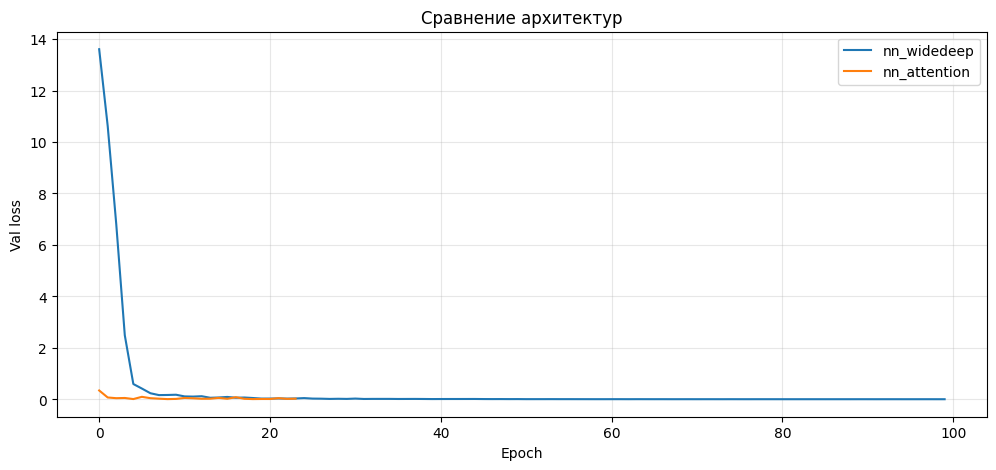

In [84]:
plt.figure(figsize=(12, 5))
for r in all_results:
    if 'history' in r:
        plt.plot(r['history']['val'], label=r['name'])
plt.xlabel('Epoch')
plt.ylabel('Val loss')
plt.legend()
plt.title('Сравнение архитектур')
plt.grid(alpha=0.3)
plt.show()

In [85]:
fe_features = ['dist_kremlin', 'dist_msk_city', 'dist_vdnkh', 'dist_luzhniki',
               'area_per_room', 'kitchen_share', 'living_share',
               'ceiling_per_area', 'district_avg_area', 'district_avg_age',
               'station_avg_area']

print("В df_sec_m:", [c for c in fe_features if c in df_sec_m.columns])
print("В df_cb:",    [c for c in fe_features if c in df_cb.columns])

В df_sec_m: ['living_share']
В df_cb: ['dist_kremlin', 'dist_msk_city', 'dist_vdnkh', 'dist_luzhniki', 'area_per_room', 'kitchen_share', 'living_share', 'ceiling_per_area', 'district_avg_area', 'district_avg_age', 'station_avg_area']


In [86]:
import numpy as np
import pandas as pd
import time
from sklearn.model_selection import train_test_split
from catboost import CatBoostRegressor
import lightgbm as lgb
import xgboost as xgb
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

# ============================================================
# 1. ДАННЫЕ (те же 70/15/15, что и везде)
# ============================================================

TARGET = 'price_rub'
df_ens = df_cb.copy()

bad = [c for c in df_ens.columns
       if isinstance(df_ens[c].dtype, pd.PeriodDtype)
       or pd.api.types.is_datetime64_any_dtype(df_ens[c])]
df_ens = df_ens.drop(columns=bad)

cat_cols = [c for c in ['district', 'okrug', 'metro_station', 'metro_line',
                        'building_type', 'renovation']
            if c in df_ens.columns]

X = df_ens.drop(columns=[TARGET])
y = np.log1p(df_ens[TARGET].values)

X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, test_size=0.3, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.5, random_state=42)

print(f"train: {X_tr.shape}, val: {X_val.shape}, test: {X_test.shape}")

# ============================================================
# 2. CatBoost с best_params от Optuna
# ============================================================

X_tr_cb = X_tr.copy(); X_val_cb = X_val.copy()
for c in cat_cols:
    X_tr_cb[c]  = X_tr_cb[c].astype(str)
    X_val_cb[c] = X_val_cb[c].astype(str)

cat_idx = [X_tr_cb.columns.get_loc(c) for c in cat_cols]

model_cb = CatBoostRegressor(
    iterations=10000, learning_rate=0.0290398, depth=7, l2_leaf_reg=4.14278,
    bagging_temperature=0.104705, random_strength=0.198779,
    loss_function='RMSE', eval_metric='MAPE',
    random_seed=42, early_stopping_rounds=300, verbose=500,
    cat_features=cat_idx,
)
t0 = time.time()
model_cb.fit(X_tr_cb, y_tr, eval_set=(X_val_cb, y_val), use_best_model=True)
print(f"\nCatBoost: {time.time()-t0:.1f} сек")
pred_cb_val = model_cb.predict(X_val_cb)

# ============================================================
# 3. LightGBM
# ============================================================

X_tr_lgb = X_tr.copy(); X_val_lgb = X_val.copy()
for c in cat_cols:
    X_tr_lgb[c]  = X_tr_lgb[c].astype('category')
    X_val_lgb[c] = X_val_lgb[c].astype('category')

model_lgb = lgb.LGBMRegressor(
    n_estimators=5000, learning_rate=0.03, num_leaves=63,
    min_child_samples=20, reg_alpha=0.1, reg_lambda=0.1,
    random_state=42, n_jobs=-1, verbose=-1,
)
t0 = time.time()
model_lgb.fit(
    X_tr_lgb, y_tr,
    eval_set=[(X_val_lgb, y_val)],
    eval_metric='mape',
    callbacks=[lgb.early_stopping(200, verbose=False)],
)
print(f"LightGBM: {time.time()-t0:.1f} сек")
pred_lgb_val = model_lgb.predict(X_val_lgb)

# ============================================================
# 4. XGBoost
# ============================================================

X_tr_xgb = X_tr.copy(); X_val_xgb = X_val.copy()
for c in cat_cols:
    X_tr_xgb[c]  = X_tr_xgb[c].astype('category')
    X_val_xgb[c] = X_val_xgb[c].astype('category')

model_xgb = xgb.XGBRegressor(
    n_estimators=5000, learning_rate=0.03, max_depth=8,
    reg_alpha=0.1, reg_lambda=1.0, random_state=42,
    tree_method='hist', enable_categorical=True,
    early_stopping_rounds=200, verbosity=0,
)
t0 = time.time()
model_xgb.fit(X_tr_xgb, y_tr, eval_set=[(X_val_xgb, y_val)], verbose=False)
print(f"XGBoost: {time.time()-t0:.1f} сек")
pred_xgb_val = model_xgb.predict(X_val_xgb)

# ============================================================
# 5. МЕТРИКИ И АНСАМБЛИ
# ============================================================

def mape_log(pred_log, y_log):
    pred = np.expm1(pred_log); true = np.expm1(y_log)
    return np.mean(np.abs((pred - true) / true)) * 100

print("\n=== Одиночные модели ===")
print(f"CatBoost: {mape_log(pred_cb_val,  y_val):.3f}%")
print(f"LightGBM: {mape_log(pred_lgb_val, y_val):.3f}%")
print(f"XGBoost:  {mape_log(pred_xgb_val, y_val):.3f}%")

# Простое среднее
pred_avg = (pred_cb_val + pred_lgb_val + pred_xgb_val) / 3
print(f"\nПростое среднее: {mape_log(pred_avg, y_val):.3f}%")

# Взвешенное — Optuna подбирает веса
def objective(trial):
    w = np.array([trial.suggest_float(f'w{i}', 0, 1) for i in range(3)])
    w = w / w.sum()
    pred_log = w[0]*pred_cb_val + w[1]*pred_lgb_val + w[2]*pred_xgb_val
    return mape_log(pred_log, y_val)

study_ens = optuna.create_study(direction='minimize')
study_ens.optimize(objective, n_trials=100)

w = np.array([study_ens.best_params[f'w{i}'] for i in range(3)])
w = w / w.sum()
print(f"\nЛучшие веса: CB={w[0]:.3f}, LGB={w[1]:.3f}, XGB={w[2]:.3f}")

pred_w = w[0]*pred_cb_val + w[1]*pred_lgb_val + w[2]*pred_xgb_val
print(f"Взвешенное среднее: {mape_log(pred_w, y_val):.3f}%")

# ============================================================
# 6. ИТОГ
# ============================================================

results = pd.DataFrame({
    'Модель': ['CatBoost', 'LightGBM', 'XGBoost',
               'Простое среднее', 'Взвешенное среднее'],
    'MAPE %': [
        mape_log(pred_cb_val, y_val),
        mape_log(pred_lgb_val, y_val),
        mape_log(pred_xgb_val, y_val),
        mape_log(pred_avg, y_val),
        mape_log(pred_w, y_val),
    ],
}).sort_values('MAPE %')

print("\n=== ИТОГ ===")
print(results.to_string(index=False))

# Сохраняем лучшие веса и предсказания для test
np.save('best_weights.npy', w)
print(f"\nВеса сохранены в best_weights.npy")

train: (35000, 41), val: (7500, 41), test: (7500, 41)
0:	learn: 0.0293425	test: 0.0290609	best: 0.0290609 (0)	total: 65.9ms	remaining: 10m 58s
500:	learn: 0.0043701	test: 0.0042859	best: 0.0042859 (500)	total: 36.3s	remaining: 11m 27s
1000:	learn: 0.0040618	test: 0.0041514	best: 0.0041514 (1000)	total: 1m 12s	remaining: 10m 55s
1500:	learn: 0.0038881	test: 0.0041206	best: 0.0041205 (1497)	total: 1m 49s	remaining: 10m 21s
2000:	learn: 0.0037417	test: 0.0041104	best: 0.0041104 (2000)	total: 2m 26s	remaining: 9m 46s
2500:	learn: 0.0036063	test: 0.0041035	best: 0.0041035 (2500)	total: 3m 3s	remaining: 9m 10s
3000:	learn: 0.0034792	test: 0.0041028	best: 0.0041023 (2978)	total: 3m 40s	remaining: 8m 34s
Stopped by overfitting detector  (300 iterations wait)

bestTest = 0.004102343031
bestIteration = 2978

Shrink model to first 2979 iterations.

CatBoost: 242.0 сек


c:\Users\Computer\Desktop\programInj\house-price-predictor-\predictor-service\venv\lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


LightGBM: 3.4 сек
XGBoost: 5.3 сек

=== Одиночные модели ===
CatBoost: 6.666%
LightGBM: 7.172%
XGBoost:  8.220%

Простое среднее: 7.004%

Лучшие веса: CB=0.871, LGB=0.128, XGB=0.001
Взвешенное среднее: 6.655%

=== ИТОГ ===
            Модель   MAPE %
Взвешенное среднее 6.655182
          CatBoost 6.666291
   Простое среднее 7.003541
          LightGBM 7.172428
           XGBoost 8.220227

Веса сохранены в best_weights.npy


---
← [Часть 6. Ансамбль CatBoost, LightGBM и XGBoost](06_ensemble.ipynb) · [Все части](README.md) · [Часть 8. Важность признаков, проверка на тесте и финальная модель](08_final_model.ipynb) →

---


# 8. Важность признаков, проверка на тесте и финальная модель

**Проект:** прогноз цены квартиры на вторичном рынке Москвы по датасету `Moscow_Real_Estate`.

**В этой части:**
- важность всех 41 признака в CatBoost;
- проверка ансамбля на тестовой выборке и смесь CatBoost с нейросетью;
- CatBoost на 20 признаках против 41 и сохранение финальной модели.

**Главный результат:** на тесте MAPE 6,69 %, R² 0,976; остаётся 41 признак (на 20 признаках — 6,84 %), модель сохраняется в `final_catboost.pkl`.

**Графики для отчёта:**
- рисунок 7 — важность признаков CatBoost (41 признак): [`figures/fig_07_catboost_feature_importance.png`](figures/fig_07_catboost_feature_importance.png)

> Код продолжает предыдущие части и использует их переменные. Результаты уже сохранены в блокноте, поэтому его можно читать без запуска. Чтобы пересчитать часть, сначала выполните в этом же ядре части 1–7 по порядку: `%run -i 01_eda.ipynb` и так далее.

← [Часть 7. Эксперименты с нейросетями](07_neural_networks.ipynb) · [Все части](README.md)

### Feature importance

                 feature  importance
              total_area   22.504116
                district   14.709886
                   okrug   13.562704
           dist_msk_city    7.879696
              renovation    6.776963
      metro_distance_min    6.359541
      months_since_start    6.034275
            dist_kremlin    4.575617
           building_type    4.327640
            to_center_km    3.614982
           dist_luzhniki    2.476777
              dist_vdnkh    1.906122
mortgage_rate_at_listing    1.293374
                     lat    0.899152
             living_area    0.423756
    district_avg_ceiling    0.391762
        district_avg_age    0.364385
       district_avg_area    0.320409
                   floor    0.266897
                     lon    0.198146
            building_age    0.100568
          ceiling_height    0.094975
             has_balcony    0.094655
           area_per_room    0.089722
            living_share    0.085508
           metro_station    0.070560
 

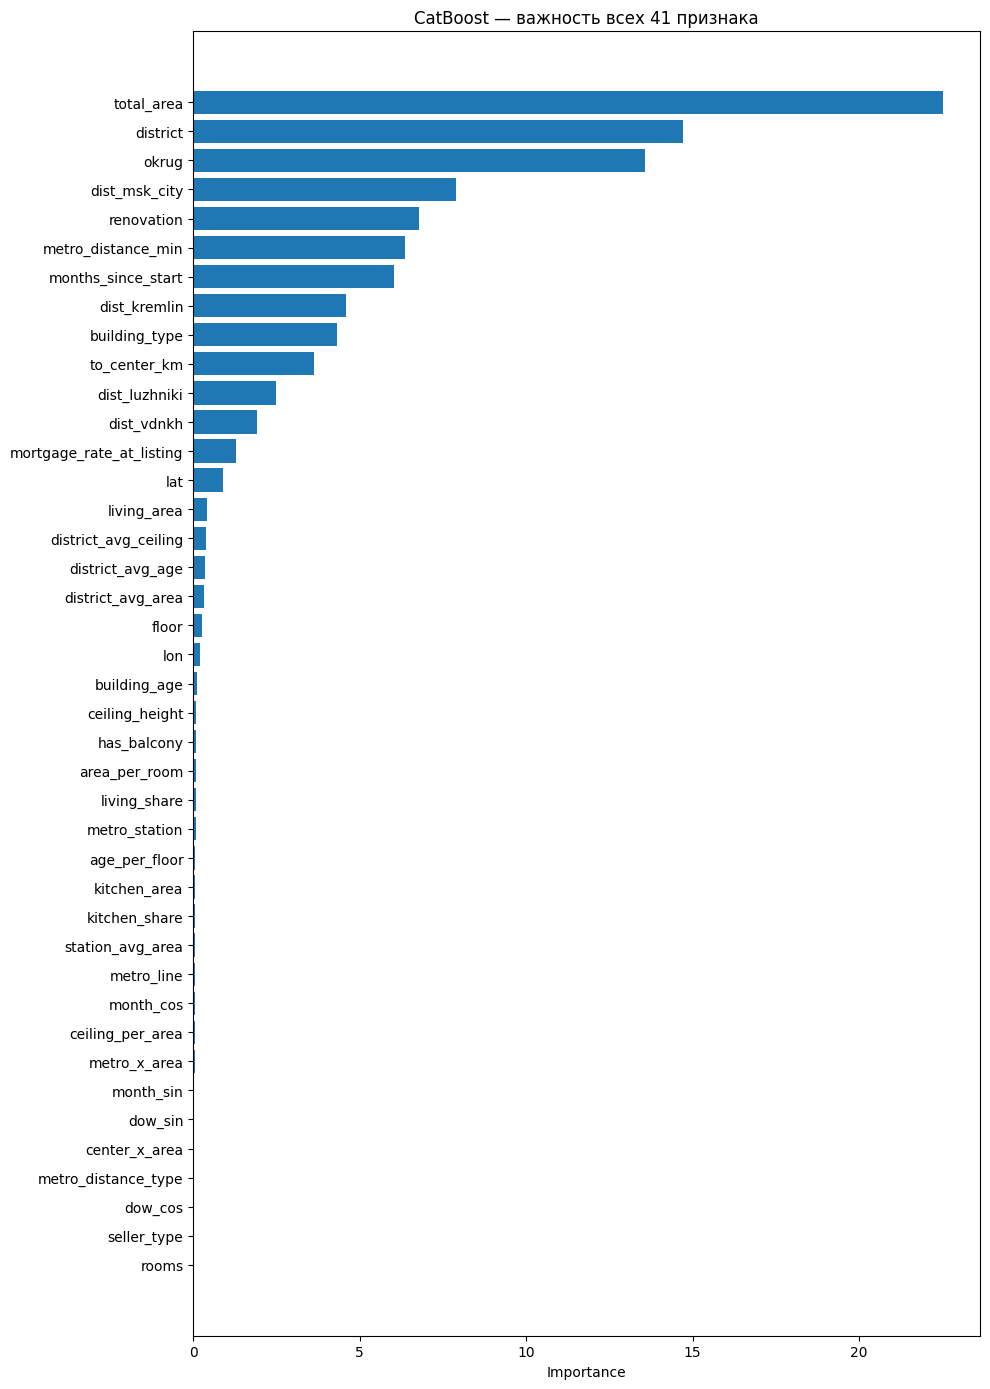

In [87]:
import pandas as pd
import matplotlib.pyplot as plt

# Обучите CatBoost на df_cb (с новыми фичами)
# и посмотрите важность
importance = pd.DataFrame({
    'feature': X_tr_cb.columns,
    'importance': model_cb.get_feature_importance(),
}).sort_values('importance', ascending=False)

print(importance.to_string(index=False))

plt.figure(figsize=(10, 14))
plt.barh(importance['feature'], importance['importance'])
plt.gca().invert_yaxis()
plt.xlabel('Importance')
plt.title('CatBoost — важность всех 41 признака')
plt.tight_layout()
plt.show()

### Проверка на тестовой

In [88]:
# Подготовка X_test для каждой модели
X_test_cb  = X_test.copy()
X_test_lgb = X_test.copy()
X_test_xgb = X_test.copy()

# CatBoost — категориальные как строки
for c in cat_cols:
    X_test_cb[c] = X_test_cb[c].astype(str)

# LightGBM и XGBoost — категориальные как 'category'
for c in cat_cols:
    X_test_lgb[c] = X_test_lgb[c].astype('category')
    X_test_xgb[c] = X_test_xgb[c].astype('category')

print("X_test подготовлен:", X_test_cb.shape)

X_test подготовлен: (7500, 41)


In [89]:
print("cat_cols:", cat_cols)
print("X_test shape:", X_test.shape)

cat_cols: ['district', 'okrug', 'metro_station', 'metro_line', 'building_type', 'renovation']
X_test shape: (7500, 41)


In [90]:
pred_cb_test  = model_cb.predict(X_test_cb)
pred_lgb_test = model_lgb.predict(X_test_lgb)
pred_xgb_test = model_xgb.predict(X_test_xgb)

# Взвешенное среднее с сохранёнными весами
w = np.load('best_weights.npy')
pred_ens_test_log = w[0]*pred_cb_test + w[1]*pred_lgb_test + w[2]*pred_xgb_test

pred_test = np.expm1(pred_ens_test_log)
true_test = np.expm1(y_test)

mae  = np.mean(np.abs(pred_test - true_test))
rmse = np.sqrt(np.mean((pred_test - true_test) ** 2))
mape = np.mean(np.abs((pred_test - true_test) / true_test)) * 100
r2   = 1 - np.sum((true_test - pred_test) ** 2) / np.sum((true_test - true_test.mean()) ** 2)

print(f"\n=== TEST SET (финальная оценка) ===")
print(f"MAE:  {mae:>12,.0f} руб")
print(f"RMSE: {rmse:>12,.0f} руб")
print(f"MAPE: {mape:>12.2f} %")
print(f"R²:   {r2:>12.4f}")


=== TEST SET (финальная оценка) ===
MAE:       884,887 руб
RMSE:    1,333,630 руб
MAPE:         6.69 %
R²:         0.9760


### CatBoost + NN1

In [91]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import QuantileTransformer
from catboost import CatBoostRegressor
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print("Device:", device)

# ============================================================
# 1. ДАННЫЕ
# ============================================================

TARGET = 'price' if 'price' in df_cb.columns else 'price_rub'
df_ens = df_cb.copy()   # датасет с новыми фичами

bad = [c for c in df_ens.columns
       if isinstance(df_ens[c].dtype, pd.PeriodDtype)
       or pd.api.types.is_datetime64_any_dtype(df_ens[c])]
df_ens = df_ens.drop(columns=bad)

cat_cols = [c for c in ['district', 'okrug', 'metro_station', 'metro_line',
                        'building_type', 'renovation']
            if c in df_ens.columns]

# Один split для всех моделей
idx_tr, idx_tmp = train_test_split(df_ens.index, test_size=0.3, random_state=42)
idx_val, idx_test = train_test_split(idx_tmp, test_size=0.5, random_state=42)
df_ens, aggregate_mappings = add_train_group_aggregates(df_ens, idx_tr)

X = df_ens.drop(columns=[TARGET])
y = np.log1p(df_ens[TARGET].values)

print(f"train: {len(idx_tr)}, val: {len(idx_val)}, test: {len(idx_test)}")

# ============================================================
# 2. CATBOOST
# ============================================================

X_tr_cb = df_ens.loc[idx_tr].drop(columns=[TARGET]).copy()
X_val_cb = df_ens.loc[idx_val].drop(columns=[TARGET]).copy()
X_test_cb = df_ens.loc[idx_test].drop(columns=[TARGET]).copy()

for c in cat_cols:
    X_tr_cb[c] = X_tr_cb[c].astype(str)
    X_val_cb[c] = X_val_cb[c].astype(str)
    X_test_cb[c] = X_test_cb[c].astype(str)

cat_idx = [X_tr_cb.columns.get_loc(c) for c in cat_cols]

model_cb = CatBoostRegressor(
    iterations=10000, learning_rate=0.0290398, depth=7, l2_leaf_reg=4.14278,
    bagging_temperature=0.104705, random_strength=0.198779,
    loss_function='RMSE', eval_metric='MAPE',
    random_seed=42, early_stopping_rounds=300, verbose=500,
    cat_features=cat_idx,
)

y_tr  = np.log1p(df_ens.loc[idx_tr,  TARGET].values)
y_val = np.log1p(df_ens.loc[idx_val, TARGET].values)
y_test = np.log1p(df_ens.loc[idx_test, TARGET].values)

model_cb.fit(X_tr_cb, y_tr, eval_set=(X_val_cb, y_val), use_best_model=True)

pred_cb_val  = model_cb.predict(X_val_cb)
pred_cb_test = model_cb.predict(X_test_cb)

# ============================================================
# 3. ПОДГОТОВКА ДАННЫХ ДЛЯ NN
# ============================================================

# Категориальные — коды
df_nn = df_ens.copy()
cat_cardinalities = {}
for c in cat_cols:
    df_nn[c] = df_nn[c].astype('category')
    cat_cardinalities[c] = len(df_nn[c].cat.categories)
    df_nn[c] = df_nn[c].cat.codes.astype('int64')

# Группы признаков
cyclic_cols = [c for c in ['month_sin', 'month_cos', 'dow_sin', 'dow_cos']
               if c in df_nn.columns]
bin_cols = [c for c in ['has_balcony', 'metro_distance_type', 'seller_type']
            if c in df_nn.columns]

excluded = set(cat_cols + cyclic_cols + bin_cols + [TARGET])
num_cols = [c for c in df_nn.columns if c not in excluded]

# Нормализация (fit только на train!)
medians = df_nn.loc[idx_tr, num_cols].median()
qt = QuantileTransformer(output_distribution='normal',
                         n_quantiles=min(1000, len(idx_tr)),
                         random_state=42)

X_num_tr   = qt.fit_transform(df_nn.loc[idx_tr,   num_cols].fillna(medians)).astype('float32')
X_num_val  = qt.transform(    df_nn.loc[idx_val,  num_cols].fillna(medians)).astype('float32')
X_num_test = qt.transform(    df_nn.loc[idx_test, num_cols].fillna(medians)).astype('float32')

X_bin_tr   = df_nn.loc[idx_tr,   bin_cols].fillna(0).astype('float32').values
X_bin_val  = df_nn.loc[idx_val,  bin_cols].fillna(0).astype('float32').values
X_bin_test = df_nn.loc[idx_test, bin_cols].fillna(0).astype('float32').values

X_cyc_tr   = df_nn.loc[idx_tr,   cyclic_cols].astype('float32').values
X_cyc_val  = df_nn.loc[idx_val,  cyclic_cols].astype('float32').values
X_cyc_test = df_nn.loc[idx_test, cyclic_cols].astype('float32').values

X_cat_tr   = df_nn.loc[idx_tr,   cat_cols].values.astype('int64')
X_cat_val  = df_nn.loc[idx_val,  cat_cols].values.astype('int64')
X_cat_test = df_nn.loc[idx_test, cat_cols].values.astype('int64')

X_cont_tr   = np.hstack([X_num_tr,   X_bin_tr,   X_cyc_tr])
X_cont_val  = np.hstack([X_num_val,  X_bin_val,  X_cyc_val])
X_cont_test = np.hstack([X_num_test, X_bin_test, X_cyc_test])

n_cont = X_cont_tr.shape[1]
card_list = [cat_cardinalities[c] for c in cat_cols]
print(f"n_cont={n_cont}, card_list={card_list}")

# ============================================================
# 4. МОДЕЛЬ NN v1 (простая, как в baseline)
# ============================================================

class FlatNet(nn.Module):
    def __init__(self, n_cont, cat_cardinalities, emb_dropout=0.1):
        super().__init__()
        self.embs = nn.ModuleList([
            nn.Embedding(card, min(50, (card + 1) // 2))
            for card in cat_cardinalities
        ])
        emb_dim = sum(e.embedding_dim for e in self.embs)
        self.emb_dropout = nn.Dropout(emb_dropout)
        self.mlp = nn.Sequential(
            nn.Linear(n_cont + emb_dim, 256),
            nn.BatchNorm1d(256), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(256, 128),
            nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(128, 64), nn.ReLU(),
            nn.Linear(64, 1),
        )

    def forward(self, x_cont, x_cat):
        embs = [e(x_cat[:, i]) for i, e in enumerate(self.embs)]
        x_cat_emb = self.emb_dropout(torch.cat(embs, dim=1))
        x = torch.cat([x_cont, x_cat_emb], dim=1)
        return self.mlp(x).squeeze(-1)


torch.manual_seed(42)
model_nn = FlatNet(n_cont, card_list).to(device)

train_loader = DataLoader(
    TensorDataset(
        torch.from_numpy(X_cont_tr), torch.from_numpy(X_cat_tr),
        torch.from_numpy(y_tr.astype('float32'))),
    batch_size=256, shuffle=True)
val_loader = DataLoader(
    TensorDataset(
        torch.from_numpy(X_cont_val), torch.from_numpy(X_cat_val),
        torch.from_numpy(y_val.astype('float32'))),
    batch_size=256, shuffle=False)

criterion = nn.HuberLoss(delta=1.0)
optimizer = torch.optim.AdamW(model_nn.parameters(), lr=5e-4, weight_decay=5e-5)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=100)

EPOCHS, PATIENCE = 100, 15
best_val, wait = float('inf'), 0

for epoch in range(EPOCHS):
    model_nn.train()
    for xc, xk, yt in train_loader:
        xc, xk, yt = xc.to(device), xk.to(device), yt.to(device)
        optimizer.zero_grad()
        loss = criterion(model_nn(xc, xk), yt)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model_nn.parameters(), 1.0)
        optimizer.step()
    scheduler.step()

    model_nn.eval()
    val_loss = 0.0
    with torch.no_grad():
        for xc, xk, yt in val_loader:
            xc, xk, yt = xc.to(device), xk.to(device), yt.to(device)
            val_loss += criterion(model_nn(xc, xk), yt).item() * xc.size(0)
    val_loss /= len(val_loader.dataset)

    if val_loss < best_val:
        best_val, wait = val_loss, 0
        torch.save(model_nn.state_dict(), 'best_nn_v1.pt')
    else:
        wait += 1
        if wait >= PATIENCE:
            print(f"NN early stop на эпохе {epoch}")
            break

    if epoch % 10 == 0:
        print(f"Epoch {epoch:3d} | val_loss={val_loss:.4f}")

# Предсказания NN на val и test
model_nn.load_state_dict(torch.load('best_nn_v1.pt'))
model_nn.eval()

def nn_predict(X_cont, X_cat):
    loader = DataLoader(
        TensorDataset(torch.from_numpy(X_cont), torch.from_numpy(X_cat)),
        batch_size=512, shuffle=False)
    preds = []
    with torch.no_grad():
        for xc, xk in loader:
            xc, xk = xc.to(device), xk.to(device)
            preds.append(model_nn(xc, xk).cpu().numpy())
    return np.concatenate(preds)

pred_nn_val  = nn_predict(X_cont_val,  X_cat_val)
pred_nn_test = nn_predict(X_cont_test, X_cat_test)

# ============================================================
# 5. МЕТРИКИ ОДИНОЧНЫХ МОДЕЛЕЙ
# ============================================================

def mape_log(pred_log, y_log):
    pred = np.expm1(pred_log); true = np.expm1(y_log)
    return np.mean(np.abs((pred - true) / true)) * 100

print(f"\n=== Одиночные модели (val) ===")
print(f"CatBoost: {mape_log(pred_cb_val, y_val):.3f}%")
print(f"NN v1:    {mape_log(pred_nn_val, y_val):.3f}%")

# ============================================================
# 6. АНСАМБЛЬ: ПОДБОР ВЕСОВ
# ============================================================

def objective(trial):
    w_cb = trial.suggest_float('w_cb', 0, 1)
    w_nn = 1 - w_cb
    pred_log = w_cb * pred_cb_val + w_nn * pred_nn_val
    return mape_log(pred_log, y_val)

study = optuna.create_study(direction='minimize')
study.optimize(objective, n_trials=100)

w_cb = study.best_params['w_cb']
w_nn = 1 - w_cb
print(f"\n=== Ансамбль (val) ===")
print(f"Веса: CatBoost={w_cb:.3f}, NN={w_nn:.3f}")
print(f"MAPE: {study.best_value:.3f}%")

# ============================================================
# 7. ПРОВЕРКА НА TEST
# ============================================================

pred_ens_val  = w_cb * pred_cb_val  + w_nn * pred_nn_val
pred_ens_test = w_cb * pred_cb_test + w_nn * pred_nn_test

print(f"\n=== TEST SET ===")
print(f"CatBoost:  {mape_log(pred_cb_test,  y_test):.3f}%")
print(f"NN v1:     {mape_log(pred_nn_test,  y_test):.3f}%")
print(f"Ансамбль:  {mape_log(pred_ens_test, y_test):.3f}%")

# ============================================================
# 8. ФИНАЛЬНАЯ ТАБЛИЦА
# ============================================================

results = pd.DataFrame({
    'Модель': ['CatBoost', 'NN v1', 'Ансамбль (val)', 'Ансамбль (test)'],
    'MAPE %': [
        mape_log(pred_cb_val, y_val),
        mape_log(pred_nn_val, y_val),
        mape_log(pred_ens_val, y_val),
        mape_log(pred_ens_test, y_test),
    ],
})
print("\n=== ИТОГ ===")
print(results.to_string(index=False))

Device: cpu
train: 35000, val: 7500, test: 7500
0:	learn: 0.0293425	test: 0.0290609	best: 0.0290609 (0)	total: 300ms	remaining: 49m 55s
500:	learn: 0.0043701	test: 0.0042859	best: 0.0042859 (500)	total: 38.3s	remaining: 12m 6s
1000:	learn: 0.0040618	test: 0.0041514	best: 0.0041514 (1000)	total: 1m 15s	remaining: 11m 19s
1500:	learn: 0.0038881	test: 0.0041206	best: 0.0041205 (1497)	total: 1m 52s	remaining: 10m 39s
2000:	learn: 0.0037417	test: 0.0041104	best: 0.0041104 (2000)	total: 2m 30s	remaining: 10m 1s
2500:	learn: 0.0036063	test: 0.0041035	best: 0.0041035 (2500)	total: 3m 7s	remaining: 9m 22s
3000:	learn: 0.0034792	test: 0.0041028	best: 0.0041023 (2978)	total: 3m 44s	remaining: 8m 44s
Stopped by overfitting detector  (300 iterations wait)

bestTest = 0.004102343031
bestIteration = 2978

Shrink model to first 2979 iterations.
n_cont=35, card_list=[129, 11, 104, 12, 6, 4]
Epoch   0 | val_loss=5.3968
Epoch  10 | val_loss=0.5013
Epoch  20 | val_loss=0.0920
Epoch  30 | val_loss=0.0124
E

### Финальный CatBoost

In [92]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from catboost import CatBoostRegressor
import time

# ============================================================
# 1. ОПРЕДЕЛЯЕМ МУСОРНЫЕ ПРИЗНАКИ
# ============================================================

# importance — из вашей обученной модели CatBoost на df_cb
low_imp = importance[importance['importance'] < 0.1]['feature'].tolist()
print(f"Удаляем {len(low_imp)} признаков:")
for c in low_imp:
    imp = importance[importance['feature'] == c]['importance'].values[0]
    print(f"  {c}: {imp:.4f}%")

# Создаём очищенный датасет
df_clean = df_cb.drop(columns=low_imp).copy()
print(f"\ndf_cb:    {df_cb.shape}")
print(f"df_clean: {df_clean.shape}")

Удаляем 20 признаков:
  ceiling_height: 0.0950%
  has_balcony: 0.0947%
  area_per_room: 0.0897%
  living_share: 0.0855%
  metro_station: 0.0706%
  age_per_floor: 0.0676%
  kitchen_area: 0.0601%
  kitchen_share: 0.0592%
  station_avg_area: 0.0587%
  metro_line: 0.0518%
  month_cos: 0.0490%
  ceiling_per_area: 0.0453%
  metro_x_area: 0.0441%
  month_sin: 0.0337%
  dow_sin: 0.0295%
  center_x_area: 0.0251%
  metro_distance_type: 0.0235%
  dow_cos: 0.0153%
  seller_type: 0.0079%
  rooms: 0.0069%

df_cb:    (50000, 42)
df_clean: (50000, 22)


In [93]:
# ============================================================
# 2. ПОДГОТОВКА ДАННЫХ
# ============================================================

TARGET = 'price' if 'price' in df_clean.columns else 'price_rub'

bad = [c for c in df_clean.columns
       if isinstance(df_clean[c].dtype, pd.PeriodDtype)
       or pd.api.types.is_datetime64_any_dtype(df_clean[c])]
df_clean = df_clean.drop(columns=bad)

# Категориальные — только те, что остались
cat_cols_clean = [c for c in ['district', 'okrug', 'metro_station', 'metro_line',
                              'building_type', 'renovation']
                  if c in df_clean.columns]
print("Категориальные:", cat_cols_clean)

X = df_clean.drop(columns=[TARGET])
y = np.log1p(df_clean[TARGET].values)

# ТОТ ЖЕ split (random_state=42) — иначе сравнение нечестное
X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, test_size=0.3, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.5, random_state=42)

# Категориальные → строки
X_tr_cb = X_tr.copy(); X_val_cb = X_val.copy(); X_test_cb = X_test.copy()
for c in cat_cols_clean:
    X_tr_cb[c]  = X_tr_cb[c].astype(str)
    X_val_cb[c] = X_val_cb[c].astype(str)
    X_test_cb[c] = X_test_cb[c].astype(str)

cat_idx = [X_tr_cb.columns.get_loc(c) for c in cat_cols_clean]

print(f"train: {X_tr.shape}, val: {X_val.shape}, test: {X_test.shape}")
print(f"Признаков: {X_tr.shape[1]}")

# ============================================================
# 3. ОБУЧЕНИЕ С ТЕМИ ЖЕ ПАРАМЕТРАМИ (Optuna best)
# ============================================================

model_clean = CatBoostRegressor(
    iterations=10000, learning_rate=0.0290398, depth=7, l2_leaf_reg=4.14278,
    bagging_temperature=0.104705, random_strength=0.198779,
    loss_function='RMSE', eval_metric='MAPE',
    random_seed=42, early_stopping_rounds=300, verbose=500,
    cat_features=cat_idx,
)

t0 = time.time()
model_clean.fit(X_tr_cb, y_tr, eval_set=(X_val_cb, y_val), use_best_model=True)
print(f"\nОбучение: {time.time()-t0:.1f} сек")

# ============================================================
# 4. МЕТРИКИ
# ============================================================

def mape_log(pred_log, y_log):
    pred = np.expm1(pred_log); true = np.expm1(y_log)
    return np.mean(np.abs((pred - true) / true)) * 100

def r2_log(pred_log, y_log):
    pred = np.expm1(pred_log); true = np.expm1(y_log)
    return 1 - np.sum((true - pred) ** 2) / np.sum((true - true.mean()) ** 2)

pred_clean_val  = model_clean.predict(X_val_cb)
pred_clean_test = model_clean.predict(X_test_cb)

print(f"\n=== CatBoost на очищенном датасете ({X.shape[1]} признаков) ===")
print(f"Val MAPE:  {mape_log(pred_clean_val, y_val):.3f}%")
print(f"Val R²:    {r2_log(pred_clean_val, y_val):.4f}")
print(f"Test MAPE: {mape_log(pred_clean_test, y_test):.3f}%")
print(f"Test R²:   {r2_log(pred_clean_test, y_test):.4f}")

# ============================================================
# 5. СРАВНЕНИЕ С ПОЛНЫМ ДАТАСЕТОМ
# ============================================================

print(f"\n=== СРАВНЕНИЕ ===")
print(f"{'Датасет':<20} {'Признаков':<12} {'Val MAPE':<12} {'Test MAPE':<12}")
print(f"{'Полный (df_cb)':<20} {df_cb.shape[1]-1:<12} {'6.665%':<12} {'6.690%':<12}")
print(f"{'Очищенный':<20} {X.shape[1]:<12} {mape_log(pred_clean_val, y_val):.3f}%{'':<7} {mape_log(pred_clean_test, y_test):.3f}%")

Категориальные: ['district', 'okrug', 'building_type', 'renovation']
train: (35000, 21), val: (7500, 21), test: (7500, 21)
Признаков: 21
0:	learn: 0.0293429	test: 0.0290602	best: 0.0290602 (0)	total: 57.7ms	remaining: 9m 36s
500:	learn: 0.0043962	test: 0.0043900	best: 0.0043900 (500)	total: 31.6s	remaining: 9m 59s
1000:	learn: 0.0041196	test: 0.0042404	best: 0.0042404 (1000)	total: 1m 6s	remaining: 9m 54s
1500:	learn: 0.0039658	test: 0.0042040	best: 0.0042038 (1496)	total: 1m 42s	remaining: 9m 41s
2000:	learn: 0.0038393	test: 0.0041900	best: 0.0041900 (2000)	total: 2m 19s	remaining: 9m 17s
2500:	learn: 0.0037250	test: 0.0041876	best: 0.0041873 (2472)	total: 3m	remaining: 9m
Stopped by overfitting detector  (300 iterations wait)

bestTest = 0.004187337541
bestIteration = 2472

Shrink model to first 2473 iterations.

Обучение: 202.4 сек

=== CatBoost на очищенном датасете (21 признаков) ===
Val MAPE:  6.820%
Val R²:    0.9756
Test MAPE: 6.870%
Test R²:   0.9758

=== СРАВНЕНИЕ ===
Датасет

Оставляем 41 признак

In [94]:
import joblib
import json

# Сохраняем модель
joblib.dump(model_cb, 'final_catboost.pkl')
print("Модель сохранена: final_catboost.pkl")
joblib.dump(qt, 'quantile_transformer.pkl')
print("Преобразователь сохранён: quantile_transformer.pkl")

with open('district_aggregates.json', 'w', encoding='utf-8') as f:
    json.dump(aggregate_mappings, f, indent=2, ensure_ascii=False)
print("Агрегаты train сохранены: district_aggregates.json")

# Метаданные
metadata = {
    'model_type': 'CatBoost',
    'n_features': X_tr_cb.shape[1],
    'n_train': len(idx_tr),
    'n_val': len(idx_val),
    'n_test': len(idx_test),
    'val_mape': float(mape_log(pred_cb_val, y_val)),
    'test_mape': float(mape_log(pred_cb_test, y_test)),
    'test_r2': float(r2_log(pred_cb_test, y_test)),
    'n_trees': model_cb.tree_count_,
    'best_params': {
        'learning_rate': 0.0290398,
        'depth': 7,
        'l2_leaf_reg': 4.14278,
        'bagging_temperature': 0.104705,
        'random_strength': 0.198779,
    },
    'note': 'Group aggregates fitted only on train; validation and test use train mappings.',
}

with open('final_metadata.json', 'w', encoding='utf-8') as f:
    json.dump(metadata, f, indent=2, ensure_ascii=False)
print("Метаданные сохранены: final_metadata.json")

Модель сохранена: final_catboost.pkl
Преобразователь сохранён: quantile_transformer.pkl
Агрегаты train сохранены: district_aggregates.json
Метаданные сохранены: final_metadata.json


---
← [Часть 7. Эксперименты с нейросетями](07_neural_networks.ipynb) · [Все части](README.md)